# Lab 7- Data Analysis


## Exercise 1: Reading

### HiggsML
In 2014, some of my colleagues from the ATLAS experiment put together a Higgs Machine Learning Challenge, which was hosted on [Kaggle](https://www.kaggle.com). Please read sections 1 and 3 (Introduction and Physics motivation; skip/skim 2) of [The Higgs boson machine learning challenge](https://proceedings.mlr.press/v42/cowa14.pdf), the organizers' write-up of the challenge. 

Kaggle is a platform for data science competitions, with cash awards for winners. Kaggle currently hosts over 50,000 public datasets and associated competitions. Later in the course we will look at a variety of problems hosted on Kaggle and similar platforms. 

### SUSY Dataset

For the next few labs we will use datasets used in the [first paper on Deep Learning in High Energy physics](https://arxiv.org/pdf/1402.4735.pdf). Please read up to the "Deep Learning" section (end of page 5). This paper demonstrates that Deep Neural Networks can learn from raw data the features that are typically used by physicists for searches for exotics particles. The authors provide the data they used for this paper. They considered two benchmark scenarios: Higgs and SUSY.

## Exercise 2: Download SUSY Dataset

The information about the dataset can be found at the [UCI Machine Learning Repository](https://archive.ics.uci.edu/ml/index.php). We'll start with the [SUSY Dataset](https://archive.ics.uci.edu/ml/datasets/SUSY). 

### Download
In a terminal, download the data directly from the source and then decompress it. For example:

* To download:
    * On Mac OS: 
    `curl http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz > SUSY.csv.gz`

    * In linux:
    `wget http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz`

* To uncompress:
`gunzip SUSY.csv.gz`

In [1]:
#!curl http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz > SUSY.csv.gz

In [2]:
#!rm SUSY.csv

In [3]:
#!gunzip SUSY.csv.gz

In [ ]:
ls -lh

The data is provided as a comma separated file.

In [5]:
filename="SUSY.csv"
# print out the first 5 lines using unix head command
!head -5  "SUSY.csv"

0.000000000000000000e+00,9.728614687919616699e-01,6.538545489311218262e-01,1.176224589347839355e+00,1.157156467437744141e+00,-1.739873170852661133e+00,-8.743090629577636719e-01,5.677649974822998047e-01,-1.750000417232513428e-01,8.100607395172119141e-01,-2.525521218776702881e-01,1.921887040138244629e+00,8.896374106407165527e-01,4.107718467712402344e-01,1.145620822906494141e+00,1.932632088661193848e+00,9.944640994071960449e-01,1.367815494537353516e+00,4.071449860930442810e-02
1.000000000000000000e+00,1.667973041534423828e+00,6.419061869382858276e-02,-1.225171446800231934e+00,5.061022043228149414e-01,-3.389389812946319580e-01,1.672542810440063477e+00,3.475464344024658203e+00,-1.219136357307434082e+00,1.295456290245056152e-02,3.775173664093017578e+00,1.045977115631103516e+00,5.680512785911560059e-01,4.819284379482269287e-01,0.000000000000000000e+00,4.484102725982666016e-01,2.053557634353637695e-01,1.321893453598022461e+00,3.775840103626251221e-01
1.000000000000000000e+00,4.4483992457389831

## Reducing the dataset

This is a rather large dataset. If you have trouble loading it, we can easily make a new file with less data.

Here we look at the size of the data

In [ ]:
!ls -lh

We see that we have 5 million datapoints.

In [7]:
!wc -l SUSY.csv

5000000 SUSY.csv


We create a new file of the first half million. This is sufficient for our needs in this lab:

In [8]:
!head -500000 SUSY.csv > SUSY-small.csv

In [ ]:
ls -lh

In [10]:
! wc -l SUSY-small.csv

500000 SUSY-small.csv


Use this file for the rest of the lab to make this run faster.

### First Look

Each row represents a LHC collision event. Each column contains some observable from that event. The variable names are ([based on documentation](https://archive.ics.uci.edu/ml/datasets/SUSY)):

In [11]:
VarNames=["signal", "l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi", "MET_rel", "axial_MET", "M_R", "M_TR_2", "R", "MT2", "S_R", "M_Delta_R", "dPhi_r_b", "cos_theta_r1"]

Some of these variables represent the "raw" kinematics of the observed final state particles, while others are "features" that are derived from these raw quantities:

In [12]:
RawNames=["l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi"]
FeatureNames=list(set(VarNames[1:]).difference(RawNames))

In [13]:
RawNames

['l_1_pT',
 'l_1_eta',
 'l_1_phi',
 'l_2_pT',
 'l_2_eta',
 'l_2_phi',
 'MET',
 'MET_phi']

In [14]:
FeatureNames

['M_R',
 'cos_theta_r1',
 'S_R',
 'dPhi_r_b',
 'M_TR_2',
 'R',
 'MT2',
 'M_Delta_R',
 'MET_rel',
 'axial_MET']

We will use pandas to read in the file, and matplotlib to make plots. The following ensures pandas is installed and sets everything up:

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

Now we can read the data into a pandas dataframe:

In [16]:
filename = "SUSY-small.csv"
df = pd.read_csv(filename, dtype='float64', names=VarNames)

You can see the data in Jupyter by just evaluating the dataframe:

In [17]:
df

,signal,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
0,0.0,0.972861,0.653855,1.176225,1.157156,-1.739873,-0.874309,0.567765,-0.175000,0.810061,-0.252552,1.921887,0.889637,0.410772,1.145621,1.932632,0.994464,1.367815,0.040714
1,1.0,1.667973,0.064191,-1.225171,0.506102,-0.338939,1.672543,3.475464,-1.219136,0.012955,3.775174,1.045977,0.568051,0.481928,0.000000,0.448410,0.205356,1.321893,0.377584
2,1.0,0.444840,-0.134298,-0.709972,0.451719,-1.613871,-0.768661,1.219918,0.504026,1.831248,-0.431385,0.526283,0.941514,1.587535,2.024308,0.603498,1.562374,1.135454,0.180910
3,1.0,0.381256,-0.976145,0.693152,0.448959,0.891753,-0.677328,2.033060,1.533041,3.046260,-1.005285,0.569386,1.015211,1.582217,1.551914,0.761215,1.715464,1.492257,0.090719
4,1.0,1.309996,-0.690089,-0.676259,1.589283,-0.693326,0.622907,1.087562,-0.381742,0.589204,1.365479,1.179295,0.968218,0.728563,0.000000,1.083158,0.043429,1.154854,0.094859
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
499995,0.0,0.719035,1.091879,0.291540,1.205962,-1.599117,-1.139445,0.424546,1.154849,0.637185,-0.091178,1.972156,0.697028,0.313636,0.988602,1.981573,0.744828,1.095080,0.006546
499996,1.0,0.910016,-0.364544,-0.777120,0.543648,-0.910632,-1.723707,2.864673,1.458272,2.176558,-0.590911,0.673695,1.662140,2.189362,1.195041,0.910815,1.181893,1.252362,0.826035
499997,1.0,0.842954,0.332476,-1.048564,1.347989,0.320496,-0.666358,0.450433,-0.411872,0.293407,0.630491,0.859920,0.403371,0.416258,0.591989,0.372003,0.716788,0.366991,0.265798
499998,0.0,1.370760,-1.162912,0.893499,2.118091,1.248496,-0.887211,0.164659,0.316840,0.215165,0.280418,3.087083,0.526929,0.151467,0.308067,3.098183,0.233042,0.876216,0.000593


The first column stores the "truth" label of whether an event was signal or not. Pandas makes it easy to create dataframes that store only the signal or background events:

In [18]:
df_sig=df[df.signal==1]
df_bkg=df[df.signal==0]

The following example plots the signal and background distributions of every variable. Note that we use VarNames[1:] to skip the first variable, which was the true label.

l_1_pT


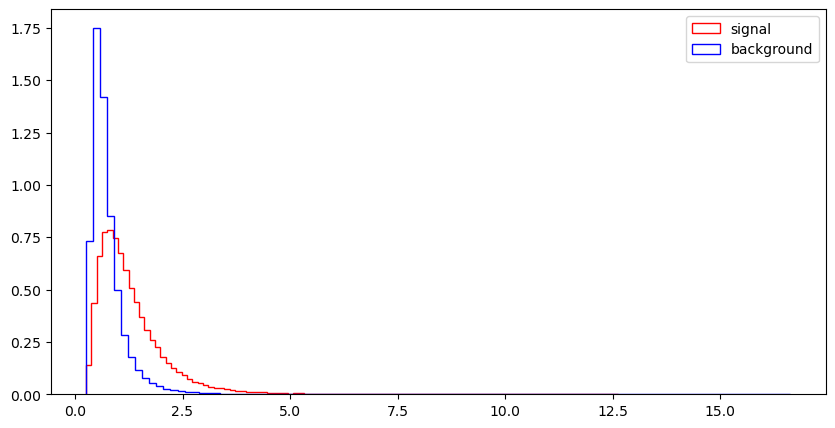

l_1_eta


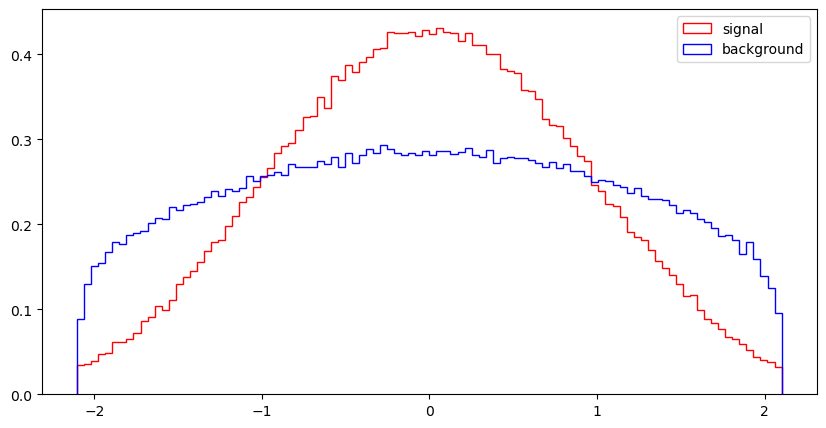

l_1_phi


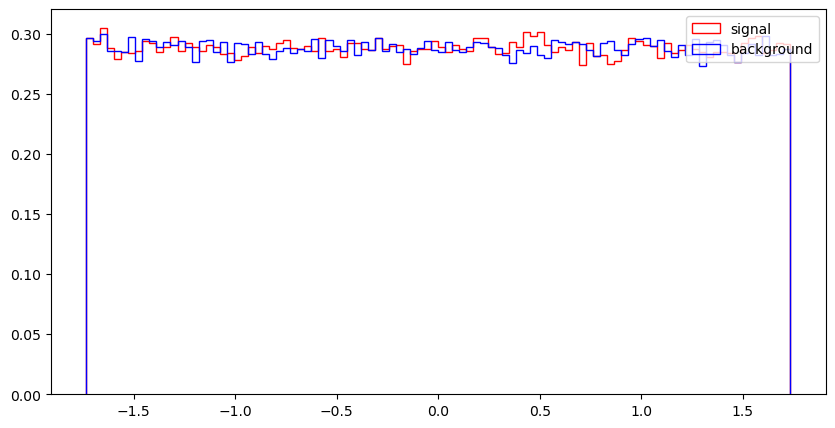

l_2_pT


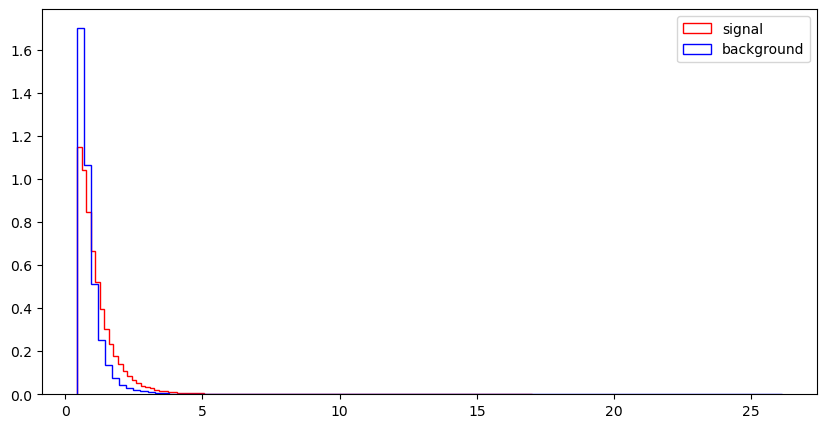

l_2_eta


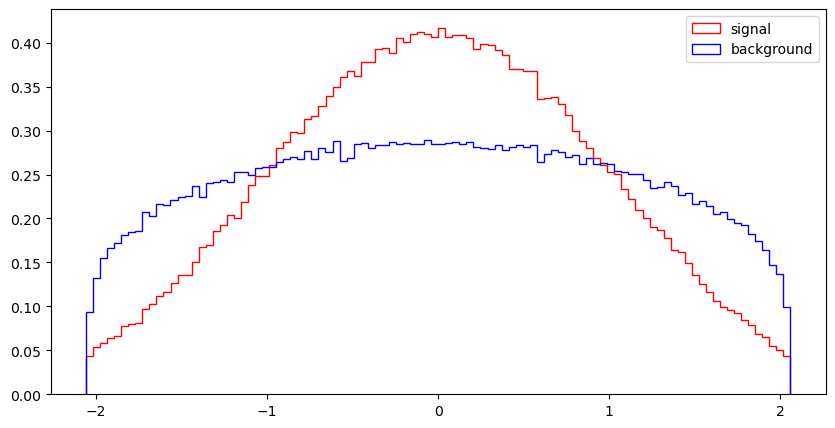

l_2_phi


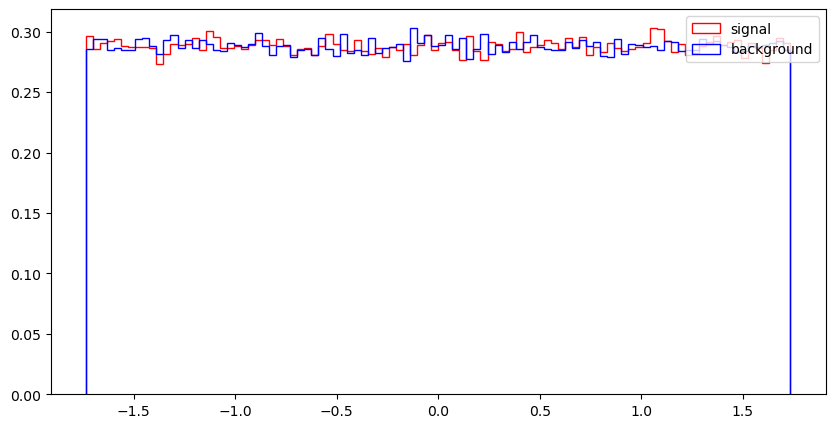

MET


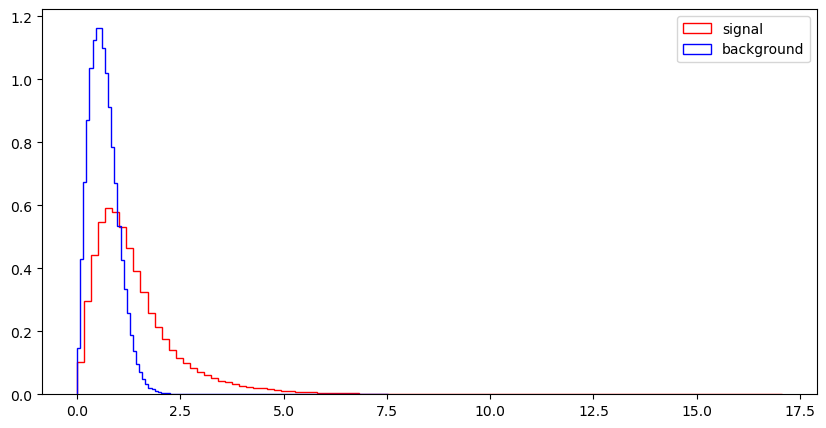

MET_phi


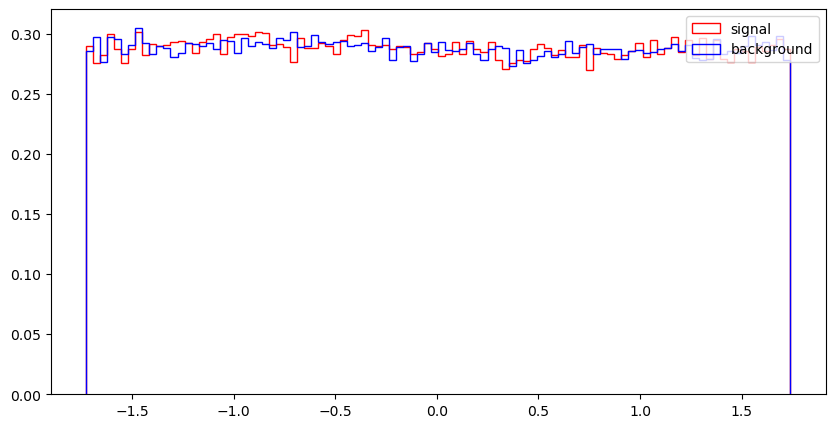

MET_rel


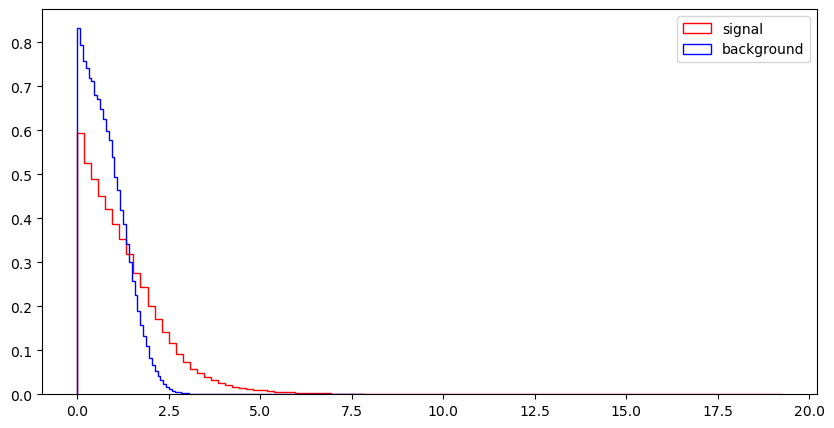

axial_MET


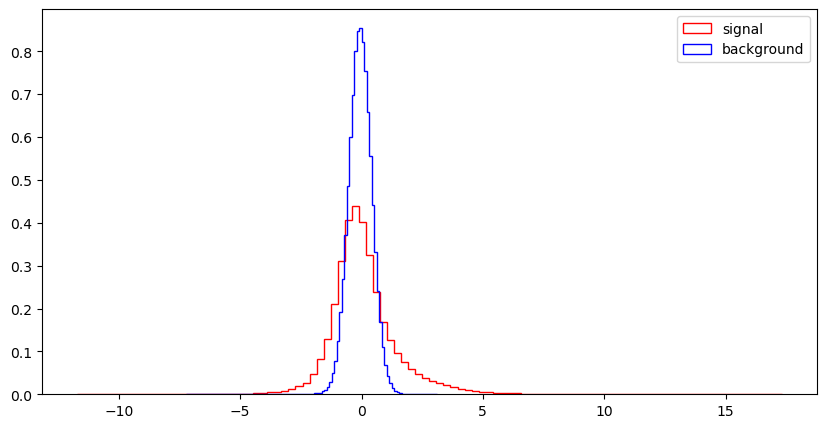

M_R


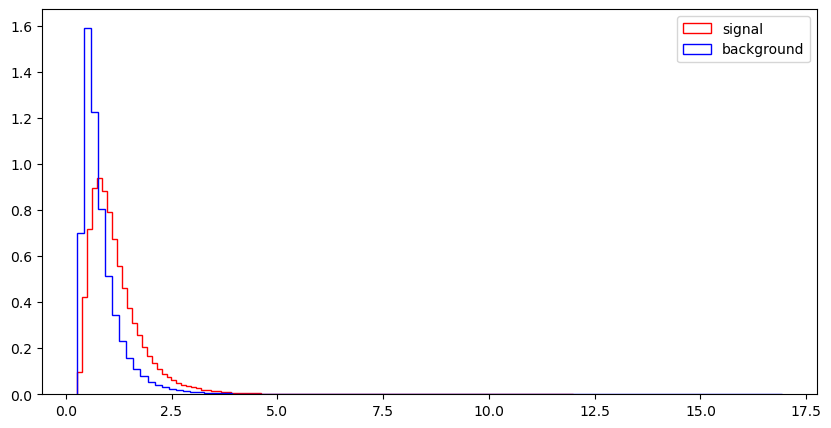

M_TR_2


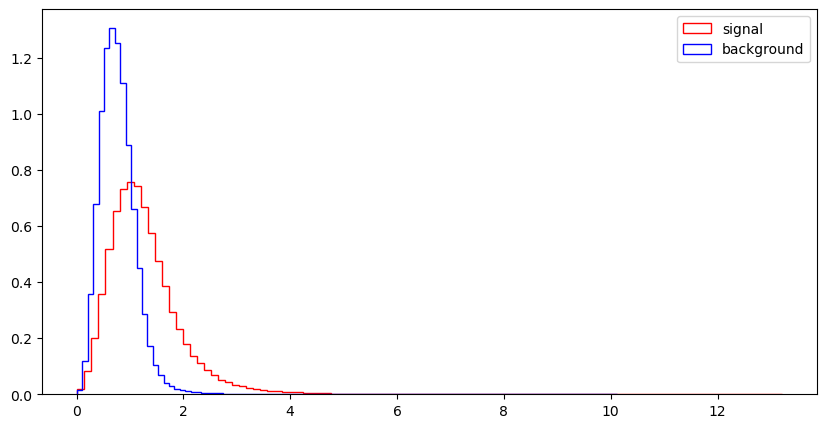

R


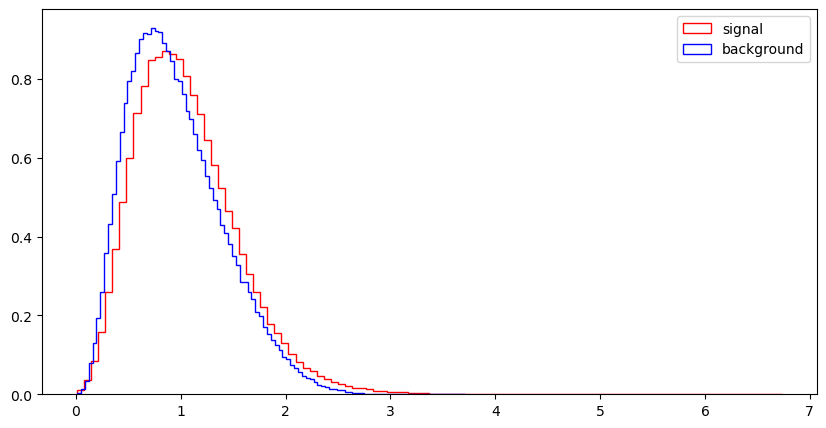

MT2


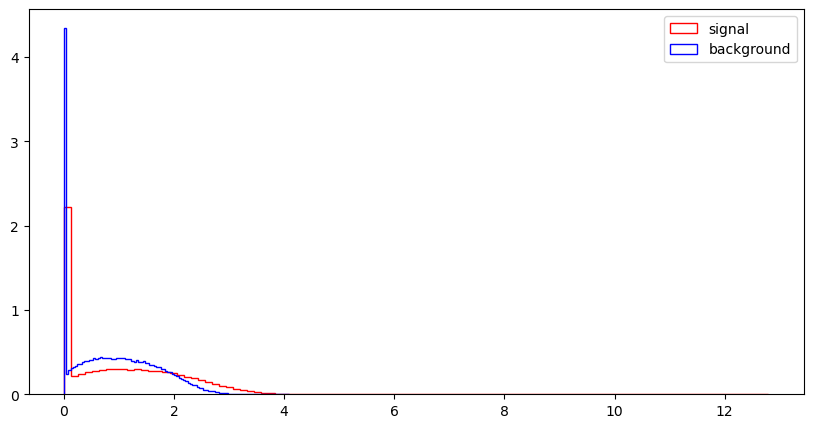

S_R


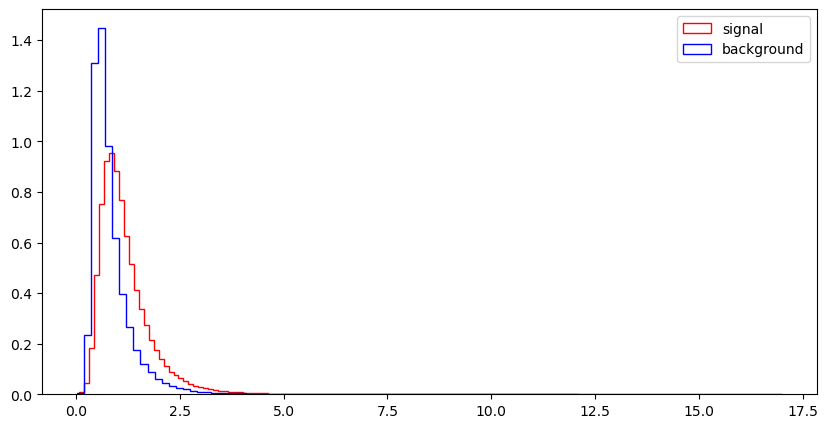

M_Delta_R


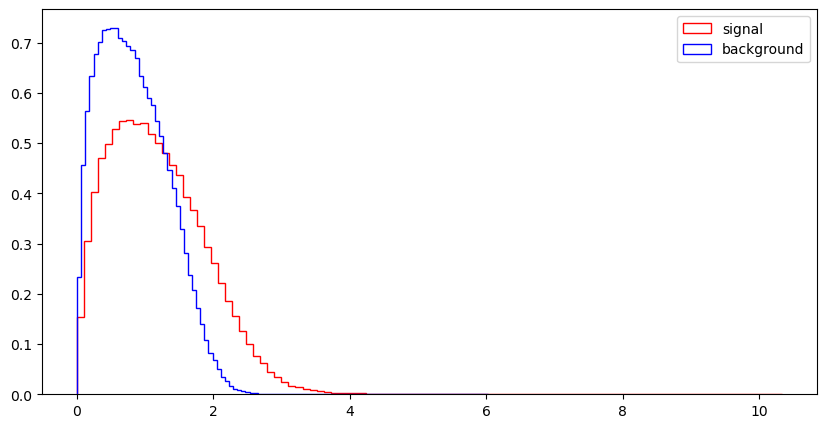

dPhi_r_b


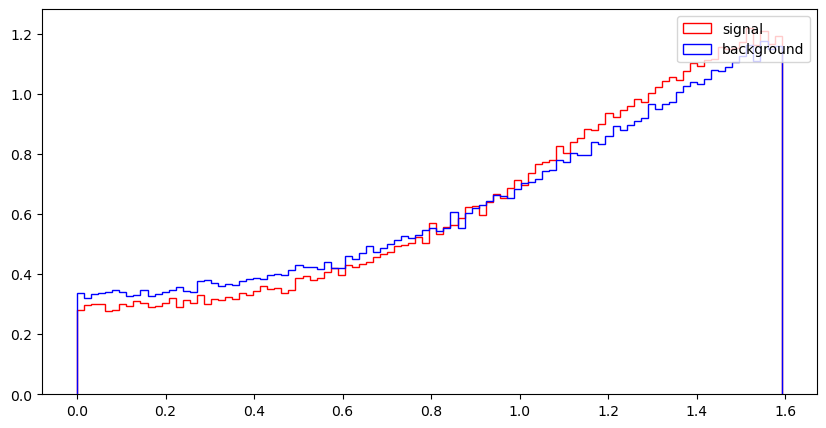

cos_theta_r1


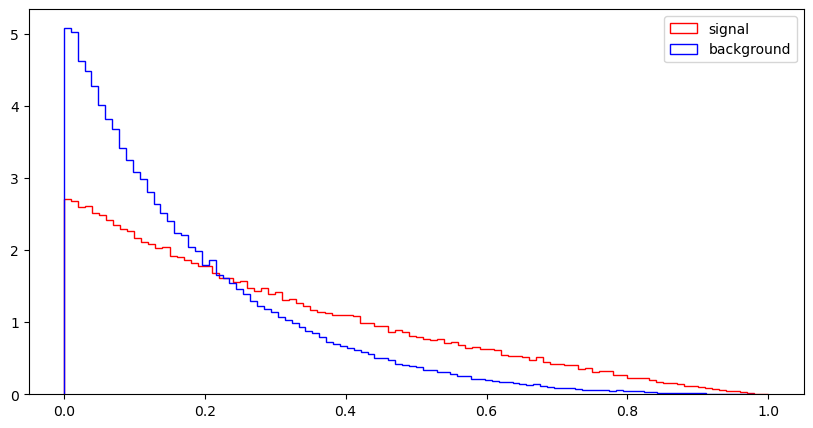

In [19]:
import numpy as np
for var in VarNames[1:]:
    print (var)
    plt.figure(figsize=(10,5))
    plt.hist(np.array(df_sig[var]),bins=100,histtype="step", color="red",label="signal",density=1, stacked=True)
    plt.hist(np.array(df_bkg[var]),bins=100,histtype="step", color="blue", label="background",density=1, stacked=True)
    plt.legend(loc='upper right')
    plt.show()

## Exercise 3: Make nice figures

Now use `matplotlib` to reproduce as closely as you can figures 5 and 6 from the paper. This exercise is intended to get you to familiarize yourself with making nicely formatted `matplotlib` figures with multiple plots. Note that the plots in the paper are actually wrong!

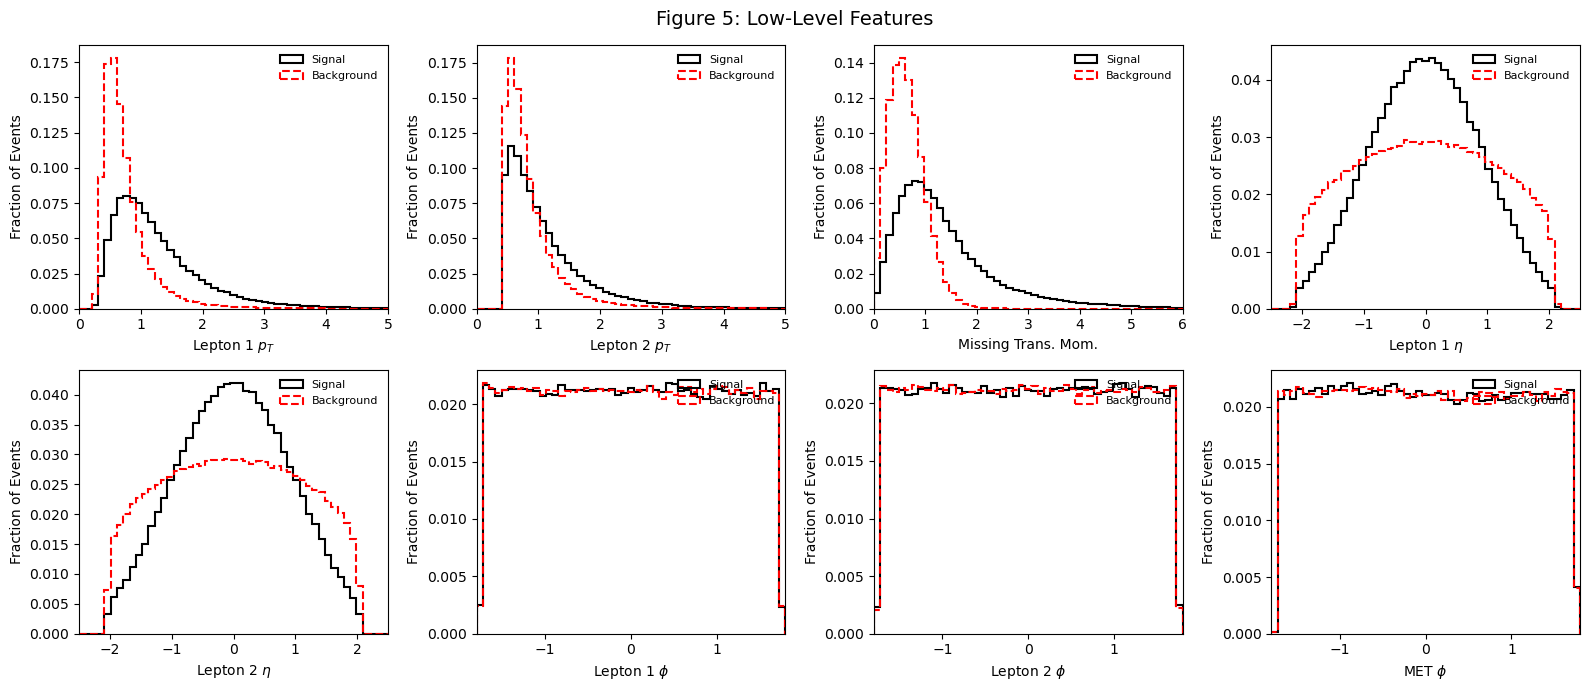

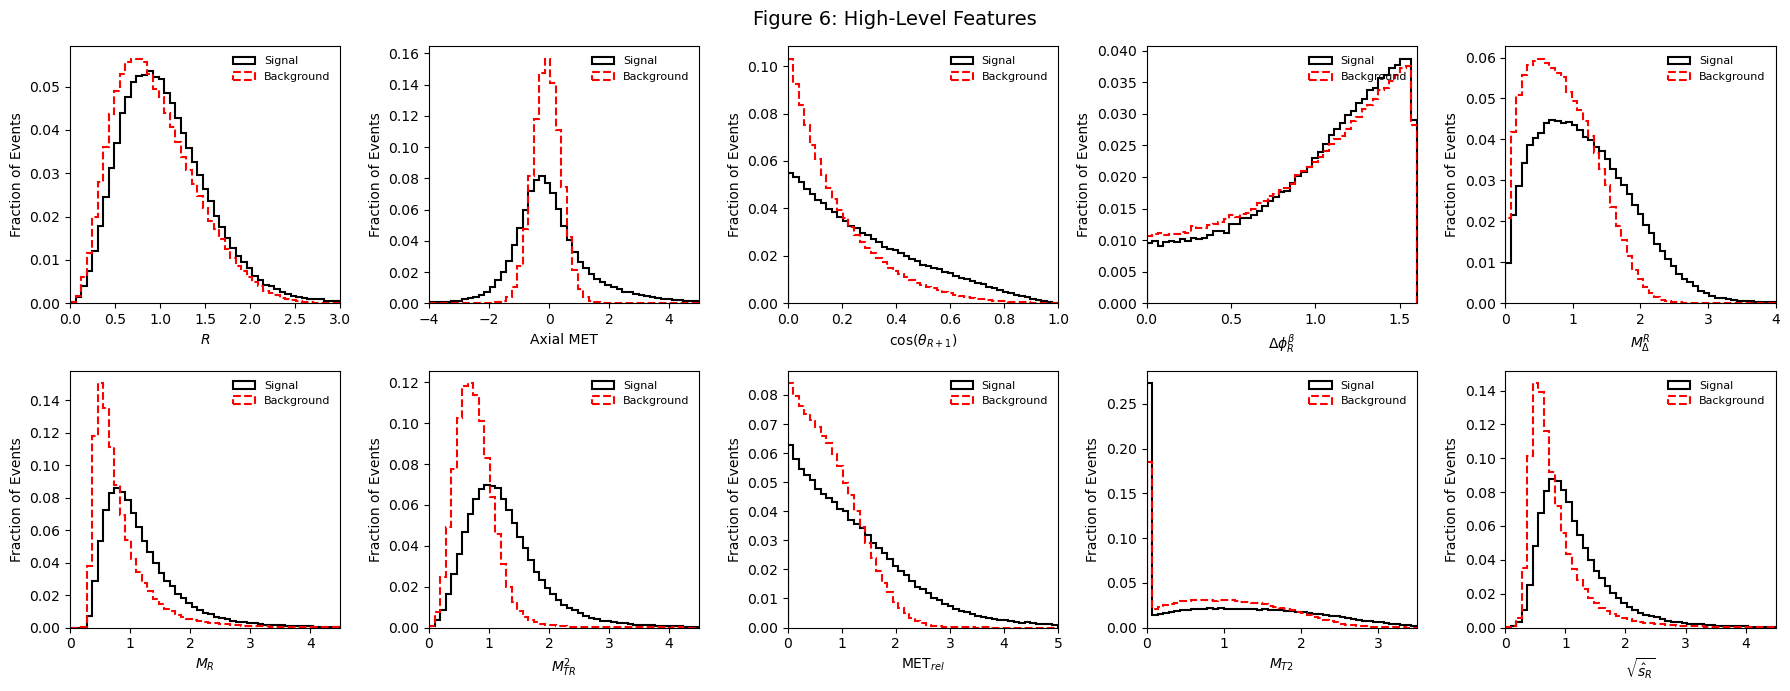

In [ ]:
# figure 5 low level features
raw_plots = [
    ("l_1_pT",  "Lepton 1 $p_T$",       (0, 5)),
    ("l_2_pT",  "Lepton 2 $p_T$",       (0, 5)),
    ("MET",     "Missing Trans. Mom.",  (0, 6)),
    ("l_1_eta", "Lepton 1 $\\eta$",     (-2.5, 2.5)),
    ("l_2_eta", "Lepton 2 $\\eta$",     (-2.5, 2.5)),
    ("l_1_phi", "Lepton 1 $\\phi$",     (-1.8, 1.8)),
    ("l_2_phi", "Lepton 2 $\\phi$",     (-1.8, 1.8)),
    ("MET_phi", "MET $\\phi$",          (-1.8, 1.8)),
]

w_sig = np.ones(len(df_sig)) / len(df_sig)
w_bkg = np.ones(len(df_bkg)) / len(df_bkg)

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
fig.suptitle("Figure 5: Low-Level Features", fontsize=14)

for ax, (var, label, xlim) in zip(axes.flat, raw_plots):
    bins = np.linspace(xlim[0], xlim[1], 50)
    ax.hist(df_sig[var], bins=bins, weights=w_sig, histtype="step", color="black", lw=1.5, label="Signal")
    ax.hist(df_bkg[var], bins=bins, weights=w_bkg, histtype="step", color="red", lw=1.5, ls="--", label="Background")
    ax.set_xlabel(label)
    ax.set_ylabel("Fraction of Events")
    ax.set_xlim(xlim)
    ax.legend(loc="upper right", frameon=False, fontsize=8)

plt.tight_layout()
plt.show()

# figure 6 high level features
hl_plots = [
    ("R",            "$R$",                  (0, 3.0)),
    ("axial_MET",    "Axial MET",            (-4.0, 5.0)),
    ("cos_theta_r1", "$\\cos(\\theta_{R+1})$", (0, 1.0)),
    ("dPhi_r_b",     "$\\Delta\\phi_R^\\beta$", (0, 1.6)),
    ("M_Delta_R",    "$M_\\Delta^R$",        (0, 4.0)),
    ("M_R",          "$M_R$",                (0, 4.5)),
    ("M_TR_2",       "$M_{TR}^2$",           (0, 4.5)),
    ("MET_rel",      "$\\text{MET}_{rel}$",  (0, 5.0)),
    ("MT2",          "$M_{T2}$",             (0, 3.5)),
    ("S_R",          "$\\sqrt{\\hat{s}_R}$", (0, 4.5)),
]

fig, axes = plt.subplots(2, 5, figsize=(18, 7))
fig.suptitle("Figure 6: High-Level Features", fontsize=14)

for ax, (var, label, xlim) in zip(axes.flat, hl_plots):
    bins = np.linspace(xlim[0], xlim[1], 50)
    ax.hist(df_sig[var], bins=bins, weights=w_sig, histtype="step", color="black", lw=1.5, label="Signal")
    ax.hist(df_bkg[var], bins=bins, weights=w_bkg, histtype="step", color="red", lw=1.5, ls="--", label="Background")
    ax.set_xlabel(label)
    ax.set_ylabel("Fraction of Events")
    ax.set_xlim(xlim)
    ax.legend(loc="upper right", frameon=False, fontsize=8)

plt.tight_layout()
plt.show()

## Exercise 4: Correlation

### Exercise 4.1

#### Part a
Write a function that creates pair plots and use it to compare variables in the SUSY sample, separately for low and high-level features. Refer to Lecture 13 for details. Do not use `seaborn`.

#### Part b
Making these plots can be slow because creating each plot initiates a full loop over the data. Make at least one modification to your function in part a to speed it up. Can you propose a different method of creating histograms that would speed up making such pair plots?

#### Part c
Which observables appear to be best for separating signal from background?

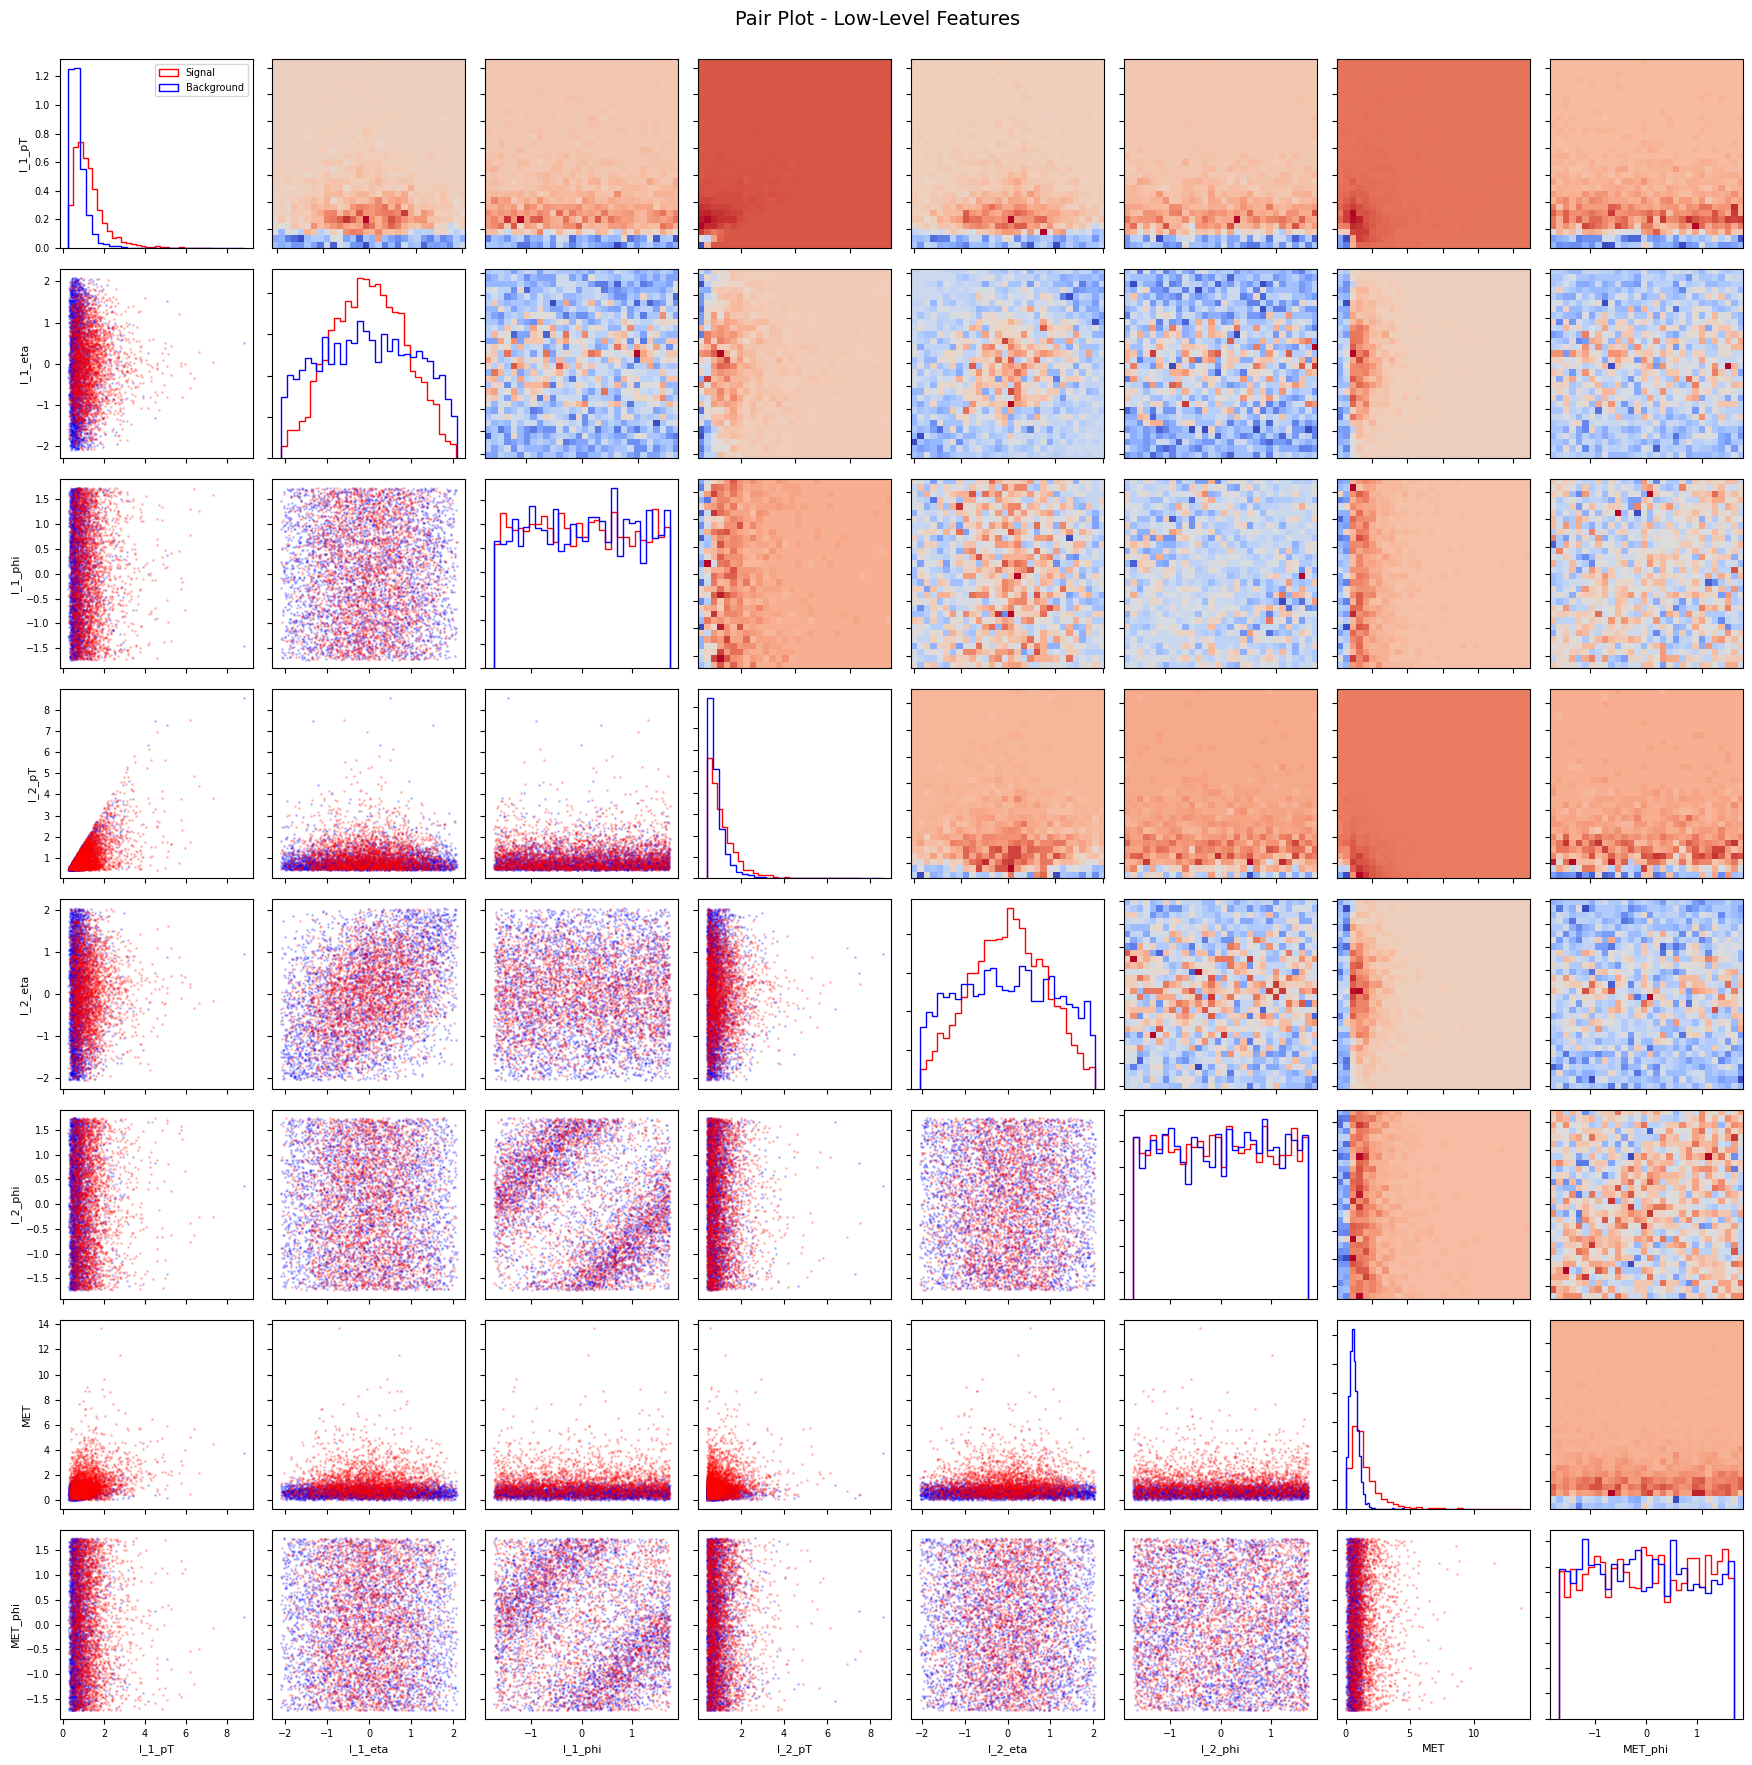

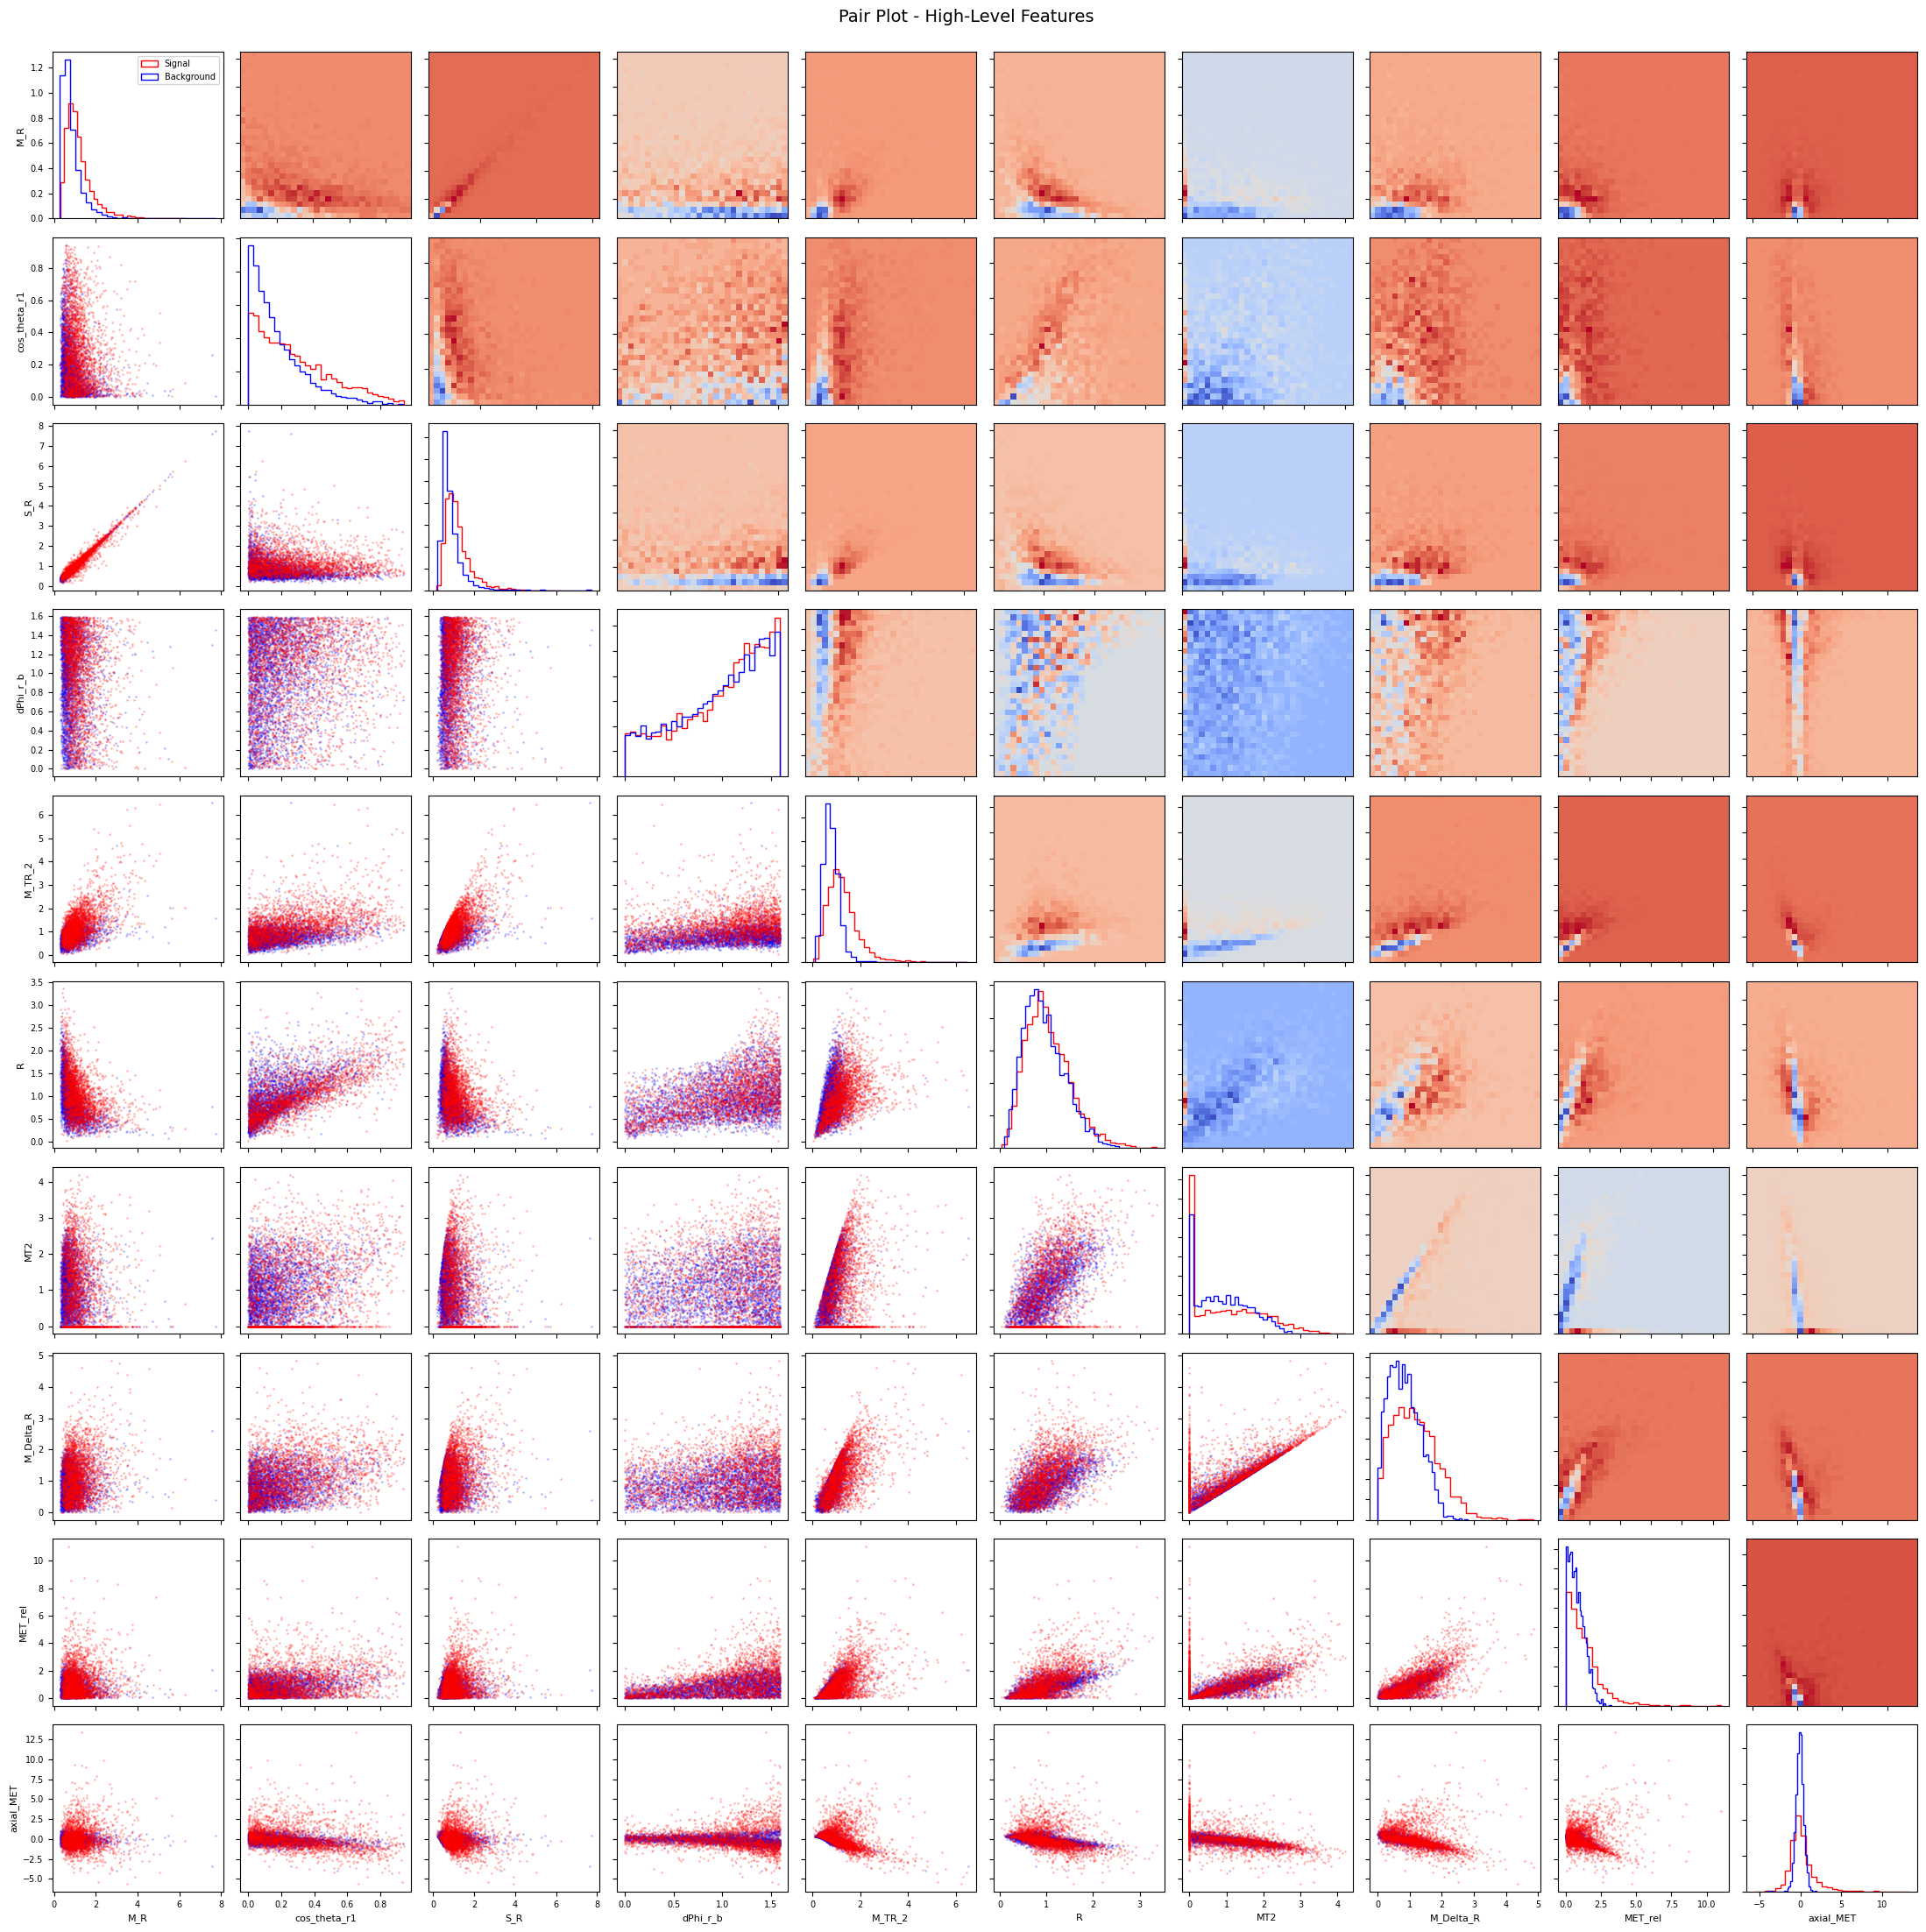

In [23]:
def make_pair_plot(df_s, df_b, var_list, title="Pair Plot", n_sample=3000, bins=30):
    k = len(var_list)
    fig, axes = plt.subplots(k, k, figsize=(2.2 * k, 2.2 * k))
    fig.suptitle(title, fontsize=14, y=1.0)

    s_sub = df_s[var_list].iloc[:n_sample]
    b_sub = df_b[var_list].iloc[:n_sample]

    for i in range(k):
        for j in range(k):
            ax = axes[i, j]
            vi, vj = var_list[i], var_list[j]

            if i == j:
                ax.hist(s_sub[vi], bins=bins, histtype="step", color="red", density=True, label="Signal")
                ax.hist(b_sub[vi], bins=bins, histtype="step", color="blue", density=True, label="Background")
                if i == 0:
                    ax.legend(loc="upper right", fontsize=7)
            elif i > j:
                ax.scatter(b_sub[vj], b_sub[vi], s=1, alpha=0.2, color="blue")
                ax.scatter(s_sub[vj], s_sub[vi], s=1, alpha=0.2, color="red")
            else:
                hs, xedges, yedges = np.histogram2d(s_sub[vj], s_sub[vi], bins=bins, density=True)
                hb, _, _ = np.histogram2d(b_sub[vj], b_sub[vi], bins=[xedges, yedges], density=True)
                ax.imshow((hs - hb).T, origin="lower",
                          extent=[xedges[0], xedges[-1], yedges[0], yedges[-1]],
                          aspect="auto", cmap="coolwarm")

            if i == k - 1:
                ax.set_xlabel(vj, fontsize=8)
            else:
                ax.set_xticklabels([])
            if j == 0:
                ax.set_ylabel(vi, fontsize=8)
            else:
                ax.set_yticklabels([])
            ax.tick_params(labelsize=7)

    plt.tight_layout()
    plt.show()

make_pair_plot(df_sig, df_bkg, RawNames, title="Pair Plot - Low-Level Features")
make_pair_plot(df_sig, df_bkg, FeatureNames, title="Pair Plot - High-Level Features")

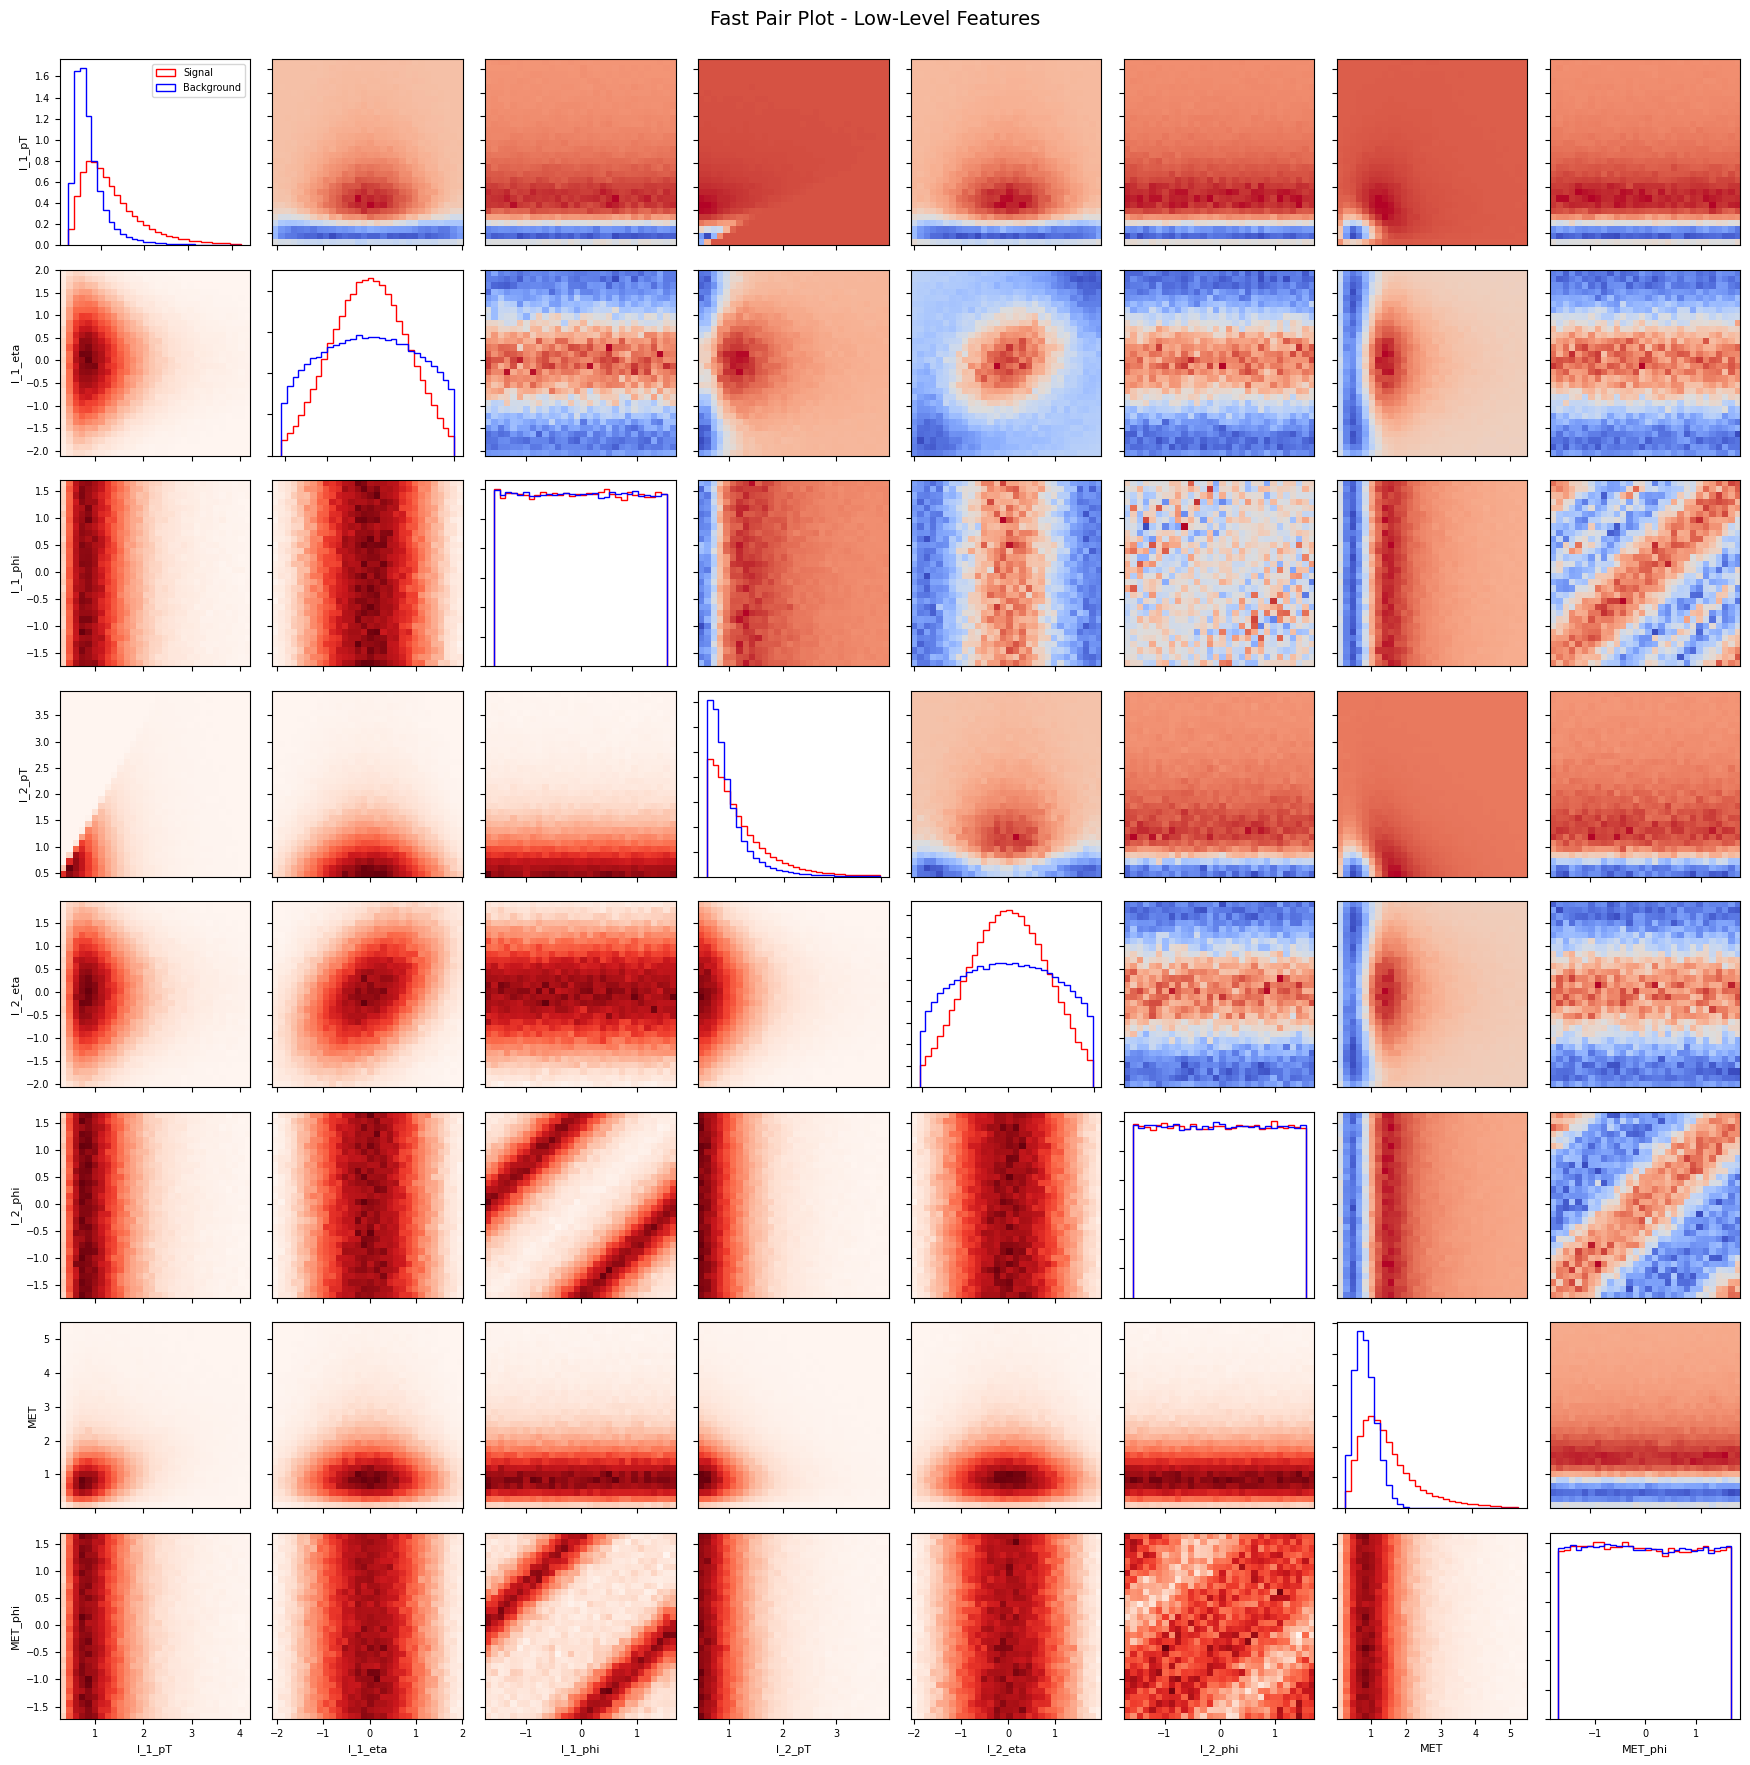

Completed in 9.16 seconds.


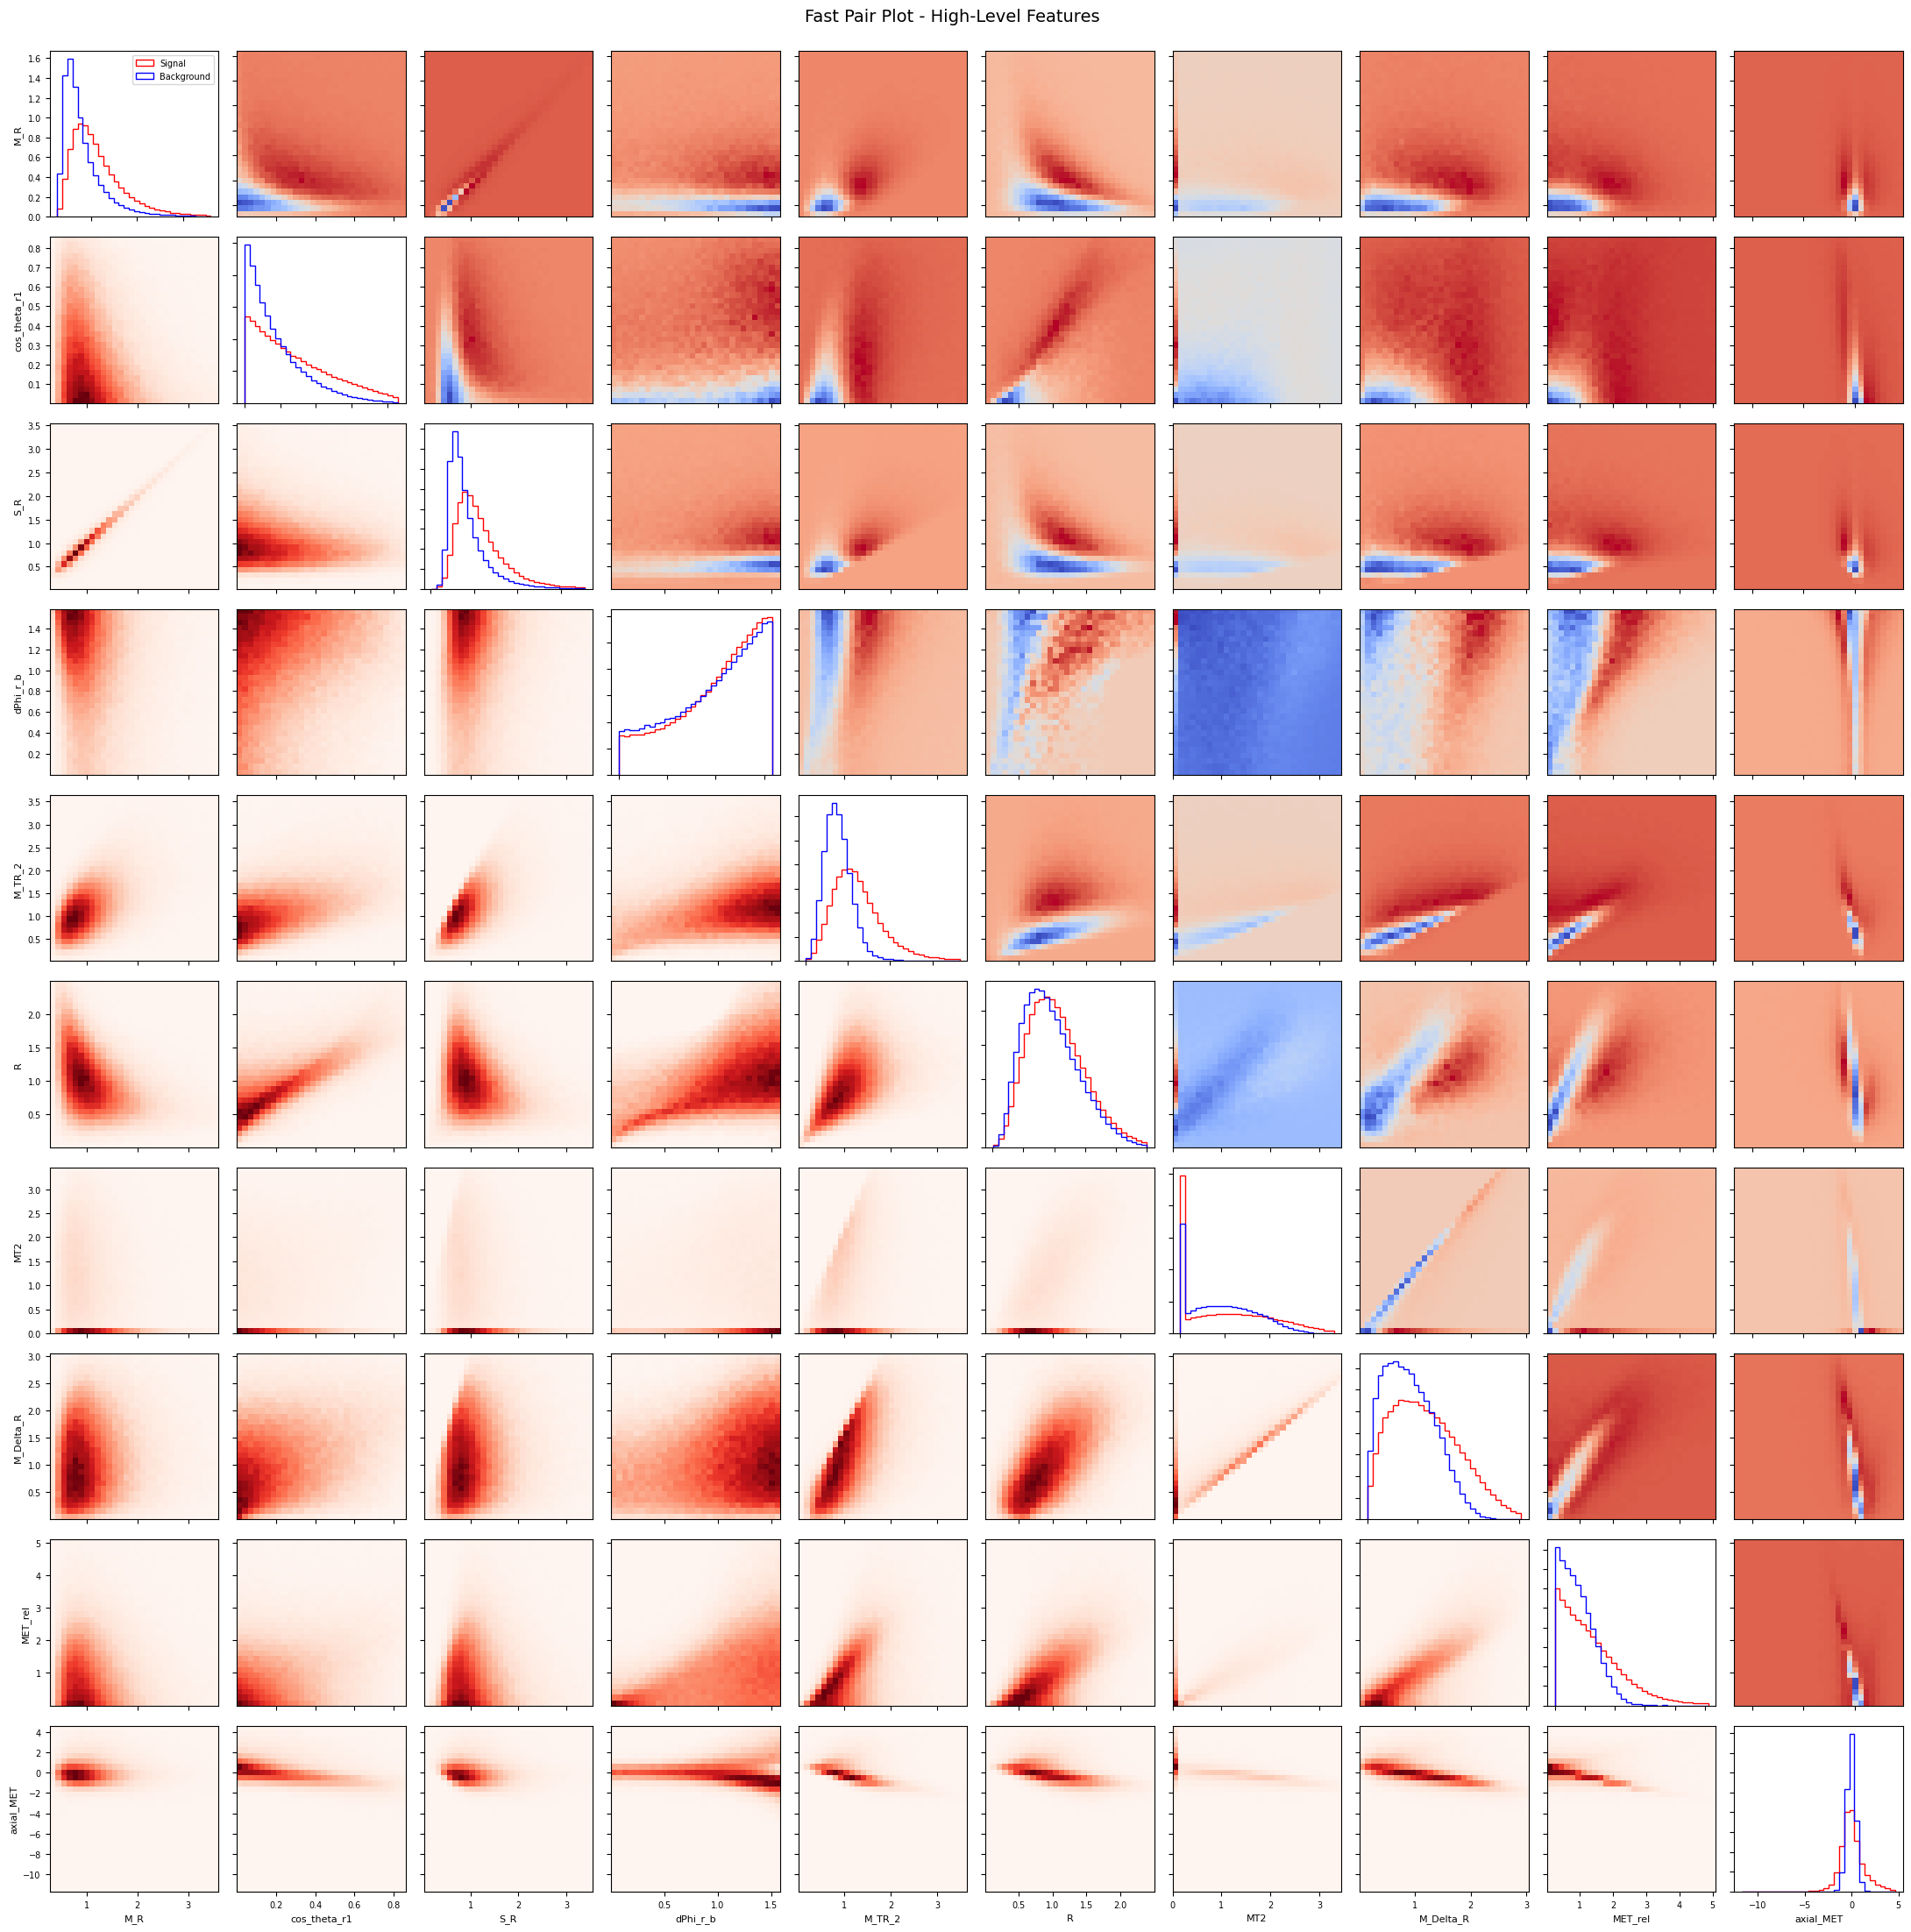

Completed in 13.66 seconds.


In [24]:
import time

def make_pair_plot_fast(df_s, df_b, var_list, title="Fast Pair Plot", bins=30):
    t0 = time.time()
    k = len(var_list)
    fig, axes = plt.subplots(k, k, figsize=(2.2 * k, 2.2 * k))
    fig.suptitle(title, fontsize=14, y=1.0)

    # convert dataframe to NumPy arrays once outside the loops
    Xs = df_s[var_list].to_numpy()
    Xb = df_b[var_list].to_numpy()

    edges = []
    for i in range(k):
        lo = min(Xs[:, i].min(), Xb[:, i].min())
        hi = max(np.percentile(Xs[:, i], 99), np.percentile(Xb[:, i], 99))
        edges.append(np.linspace(lo, hi, bins + 1))

    for i in range(k):
        # diagonal 1D histogram
        ax_diag = axes[i, i]
        ax_diag.hist(Xs[:, i], bins=edges[i], histtype="step", color="red", density=True, label="Signal")
        ax_diag.hist(Xb[:, i], bins=edges[i], histtype="step", color="blue", density=True, label="Background")
        if i == 0:
            ax_diag.legend(loc="upper right", fontsize=7)

        # only loop over j < i and reuse the transpose for the upper triangle
        for j in range(i):
            hs, _, _ = np.histogram2d(Xs[:, j], Xs[:, i], bins=[edges[j], edges[i]], density=True)
            hb, _, _ = np.histogram2d(Xb[:, j], Xb[:, i], bins=[edges[j], edges[i]], density=True)
            diff = hs - hb

            # lower triangle signal 2D histogram
            axes[i, j].imshow(hs.T, origin="lower",
                              extent=[edges[j][0], edges[j][-1], edges[i][0], edges[i][-1]],
                              aspect="auto", cmap="Reds")
            # upper triangle difference 2D histogram
            axes[j, i].imshow(diff, origin="lower",
                              extent=[edges[i][0], edges[i][-1], edges[j][0], edges[j][-1]],
                              aspect="auto", cmap="coolwarm")

    for i in range(k):
        for j in range(k):
            ax = axes[i, j]
            if i == k - 1:
                ax.set_xlabel(var_list[j], fontsize=8)
            else:
                ax.set_xticklabels([])
            if j == 0:
                ax.set_ylabel(var_list[i], fontsize=8)
            else:
                ax.set_yticklabels([])
            ax.tick_params(labelsize=7)

    plt.tight_layout()
    plt.show()
    print(f"Completed in {time.time() - t0:.2f} seconds.")

make_pair_plot_fast(df_sig, df_bkg, RawNames, title="Fast Pair Plot - Low-Level Features")
make_pair_plot_fast(df_sig, df_bkg, FeatureNames, title="Fast Pair Plot - High-Level Features")

To speed up the function, I converted the DataFrames to NumPy arrays once before the loop, used histogram2d instead of scatter, and only looped over j < i since the upper triangle is just the transpose. Another way to make histograms faster would be to map all data points to integer bin indices once up front (((x - min) / width).astype(int)) so we don't have to search for bin edges on every pair.

### Exercise 4.2

#### Part a
Install [tabulate](https://github.com/astanin/python-tabulate). 

#### Part b
Use numpy to compute the [covariance matrix](https://numpy.org/doc/stable/reference/generated/numpy.cov.html) and [correlation matrix](https://numpy.org/doc/stable/reference/generated/numpy.corrcoef.html) between all observables, and separately between low and high-level features.

#### Part c
Use tabulate to create a well formatted table of the covariance and correlation matrices, with nice headings and appropriate significant figures. Embed the table into this notebook.

#### Part d
Write a function that takes a dataset and appropriate arguments and performs steps b and c.  

Hint: Example code for embedding a `tabulate` table into a notebook:

In [25]:
from IPython.display import HTML, display
import tabulate

def show_cov_and_corr(dataset, var_names, title=""):
    X = dataset[var_names].to_numpy()
    cov = np.cov(X, rowvar=False)
    corr = np.corrcoef(X, rowvar=False)

    headers = ["Variable"] + list(var_names)
    cov_table = [[var_names[i]] + [f"{cov[i, j]:.3f}" for j in range(len(var_names))] for i in range(len(var_names))]
    corr_table = [[var_names[i]] + [f"{corr[i, j]:.3f}" for j in range(len(var_names))] for i in range(len(var_names))]

    print(f"{title} - Covariance Matrix")
    display(HTML(tabulate.tabulate(cov_table, headers=headers, tablefmt="html")))

    print(f"{title} - Correlation Matrix")
    display(HTML(tabulate.tabulate(corr_table, headers=headers, tablefmt="html")))
    return cov, corr

cov_all, corr_all = show_cov_and_corr(df, VarNames[1:], "All Observables")
cov_raw, corr_raw = show_cov_and_corr(df, RawNames, "Low-Level Features")
cov_hl, corr_hl   = show_cov_and_corr(df, FeatureNames, "High-Level Features")

All Observables - Covariance Matrix


Variable,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,0.467,-0,0,0.305,-0,0.001,0.228,-0.001,0.098,-0.01,0.364,0.287,-0.06,-0.012,0.343,0.098,-0.047,0.022
l_1_eta,-0,1.004,-0.001,-0,0.408,-0.001,-0.002,-0.001,-0.001,-0.001,-0.001,-0.001,0,0,-0.001,-0.001,-0.001,0
l_1_phi,0,-0.001,1.004,0.001,0,-0.267,0.001,-0.185,0.001,-0.002,0.001,0.001,0,0.001,0.001,0.001,0.001,0
l_2_pT,0.305,-0,0.001,0.425,-0.001,0,0.079,-0.002,-0.001,0.051,0.325,0.163,-0.099,-0.069,0.322,0.006,-0.004,-0.028
l_2_eta,-0,0.408,0,-0.001,1.006,0,0,-0,0.001,-0.001,-0.001,0,0,0.001,-0.001,0.001,-0,0
l_2_phi,0.001,-0.001,-0.267,0,0,1.004,-0,-0.035,0.001,-0.002,0.001,0.001,0.001,0.002,0.001,0.001,-0,0
MET,0.228,-0.002,0.001,0.079,0,-0,0.762,-0.003,0.546,0.154,0.145,0.365,0.188,0.155,0.166,0.315,0.146,0.073
MET_phi,-0.001,-0.001,-0.185,-0.002,-0,-0.035,-0.003,1.003,-0.005,-0,-0.001,-0.001,-0,0,-0.002,-0.001,-0.002,0
MET_rel,0.098,-0.001,0.001,-0.001,0.001,0.001,0.546,-0.005,0.79,-0.12,0.044,0.302,0.249,0.409,0.082,0.415,0.146,0.055
axial_MET,-0.01,-0.001,-0.002,0.051,-0.001,-0.002,0.154,-0,-0.12,1.005,0.017,-0.185,-0.181,-0.461,-0.041,-0.233,-0.025,-0.054


All Observables - Correlation Matrix


Variable,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,1,-0.001,0,0.684,-0.001,0.001,0.383,-0.001,0.16,-0.014,0.851,0.723,-0.186,-0.021,0.811,0.229,-0.157,0.165
l_1_eta,-0.001,1,-0.001,-0,0.406,-0.001,-0.002,-0.001,-0.002,-0.001,-0.001,-0.001,0.001,0,-0.001,-0.002,-0.002,0.002
l_1_phi,0,-0.001,1,0.002,0,-0.266,0.001,-0.184,0.001,-0.002,0.002,0.001,0,0.001,0.002,0.001,0.002,0.001
l_2_pT,0.684,-0,0.002,1,-0.001,0,0.14,-0.002,-0.001,0.078,0.797,0.43,-0.324,-0.123,0.799,0.014,-0.013,-0.217
l_2_eta,-0.001,0.406,0,-0.001,1,0,0,-0,0.001,-0.001,-0.001,0,0.001,0.002,-0.001,0.001,-0.001,0.001
l_2_phi,0.001,-0.001,-0.266,0,0,1,-0,-0.035,0.002,-0.002,0.001,0.001,0.001,0.003,0.001,0.002,-0.001,0
MET,0.383,-0.002,0.001,0.14,0,-0,1,-0.003,0.704,0.176,0.264,0.72,0.457,0.206,0.307,0.579,0.383,0.425
MET_phi,-0.001,-0.001,-0.184,-0.002,-0,-0.035,-0.003,1,-0.005,-0,-0.002,-0.002,-0,0,-0.003,-0.001,-0.004,0.001
MET_rel,0.16,-0.002,0.001,-0.001,0.001,0.002,0.704,-0.005,1,-0.134,0.078,0.584,0.595,0.535,0.15,0.748,0.378,0.316
axial_MET,-0.014,-0.001,-0.002,0.078,-0.001,-0.002,0.176,-0,-0.134,1,0.027,-0.317,-0.383,-0.535,-0.067,-0.373,-0.057,-0.272


Low-Level Features - Covariance Matrix


...

Variable,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi
l_1_pT,1,-0.001,0,0.684,-0.001,0.001,0.383,-0.001
l_1_eta,-0.001,1,-0.001,-0,0.406,-0.001,-0.002,-0.001
l_1_phi,0,-0.001,1,0.002,0,-0.266,0.001,-0.184
l_2_pT,0.684,-0,0.002,1,-0.001,0,0.14,-0.002
l_2_eta,-0.001,0.406,0,-0.001,1,0,0,-0
l_2_phi,0.001,-0.001,-0.266,0,0,1,-0,-0.035
MET,0.383,-0.002,0.001,0.14,0,-0,1,-0.003
MET_phi,-0.001,-0.001,-0.184,-0.002,-0,-0.035,-0.003,1


High-Level Features - Covariance Matrix


Variable,M_R,cos_theta_r1,S_R,dPhi_r_b,M_TR_2,R,MT2,M_Delta_R,MET_rel,axial_MET
M_R,0.392,-0.014,0.38,-0.029,0.21,-0.113,-0.037,0.074,0.044,0.017
cos_theta_r1,-0.014,0.039,-0.01,0.009,0.052,0.058,0.045,0.039,0.055,-0.054
S_R,0.38,-0.01,0.382,-0.003,0.228,-0.083,-0.011,0.096,0.082,-0.041
dPhi_r_b,-0.029,0.009,-0.003,0.19,0.058,0.087,0.021,0.042,0.146,-0.025
M_TR_2,0.21,0.052,0.228,0.058,0.338,0.104,0.189,0.242,0.302,-0.185
R,-0.113,0.058,-0.083,0.087,0.104,0.222,0.232,0.165,0.249,-0.181
MT2,-0.037,0.045,-0.011,0.021,0.189,0.232,0.738,0.433,0.409,-0.461
M_Delta_R,0.074,0.039,0.096,0.042,0.242,0.165,0.433,0.389,0.415,-0.233
MET_rel,0.044,0.055,0.082,0.146,0.302,0.249,0.409,0.415,0.79,-0.12
axial_MET,0.017,-0.054,-0.041,-0.025,-0.185,-0.181,-0.461,-0.233,-0.12,1.005


High-Level Features - Correlation Matrix


Variable,M_R,cos_theta_r1,S_R,dPhi_r_b,M_TR_2,R,MT2,M_Delta_R,MET_rel,axial_MET
M_R,1,-0.116,0.981,-0.106,0.577,-0.383,-0.068,0.189,0.078,0.027
cos_theta_r1,-0.116,1,-0.085,0.106,0.451,0.627,0.264,0.319,0.316,-0.272
S_R,0.981,-0.085,1,-0.013,0.635,-0.287,-0.021,0.249,0.15,-0.067
dPhi_r_b,-0.106,0.106,-0.013,1,0.229,0.424,0.056,0.155,0.378,-0.057
M_TR_2,0.577,0.451,0.635,0.229,1,0.38,0.379,0.668,0.584,-0.317
R,-0.383,0.627,-0.287,0.424,0.38,1,0.574,0.564,0.595,-0.383
MT2,-0.068,0.264,-0.021,0.056,0.379,0.574,1,0.809,0.535,-0.535
M_Delta_R,0.189,0.319,0.249,0.155,0.668,0.564,0.809,1,0.748,-0.373
MET_rel,0.078,0.316,0.15,0.378,0.584,0.595,0.535,0.748,1,-0.134
axial_MET,0.027,-0.272,-0.067,-0.057,-0.317,-0.383,-0.535,-0.373,-0.134,1


## Exercise 5: Selection

### Exercise 5.1

Part a
By looking at the signal/background distributions for each observable (e.g. $x$) determine which selection criteria would be optimal: 

1. $x > x_c$
2. $x < x_c$
3. $|x - \mu| > x_c$
4. $|x - \mu| < x_c$

where $x_c$ is value to be determined below.

### Exercise 5.2

Plot the True Positive Rate (TPR) (aka signal efficiency $\epsilon_S(x_c)$) and False Positive Rate (FPR) (aka background efficiency $\epsilon_B(x_c)$) as function of $x_c$ for applying the strategy in Exercise 5.1 to each observable. 

### Exercise 5.3
Assume 4 different scenarios corresponding to different numbers of signal and background events expected in data:

1. Expect $N_S=10$, $N_B=100$.
1. Expect $N_S=100$, $N_B=1000$.
1. Expect $N_S=1000$, $N_B=10000$.
1. Expect $N_S=10000$, $N_B=100000$.

Plot the significance ($\sigma_{S'}$) for each observable as function of $x_c$ for each scenario, where 

$\sigma_{S'}= \frac{N'_S}{\sqrt{N'_S+N'_B}}$

and $N'_{S,B} = \epsilon_{S,B}(x_c) * N_{S,B}$.

Based on the signal and background distributions, for most variables like lepton pT, MET, and the high-level mass features, we want an upper-tail cut ($x > x_c$) because the signal has a heavier right tail. For dPhi_r_b we use a lower-tail cut ($x < x_c$) since the background spikes near the upper boundary while signal leans towards smaller values. For axial_MET, a two-sided tail cut ($\vert{}x - \mu\vert{} > x_c$) works best because the background is tightly peaked at zero with signal spread wider on both sides. Finally, for the eta variables, we use a central-window cut ($\vert{}x - \mu\vert{} < x_c$) since signal leptons are more central around zero while background spreads out to larger values.

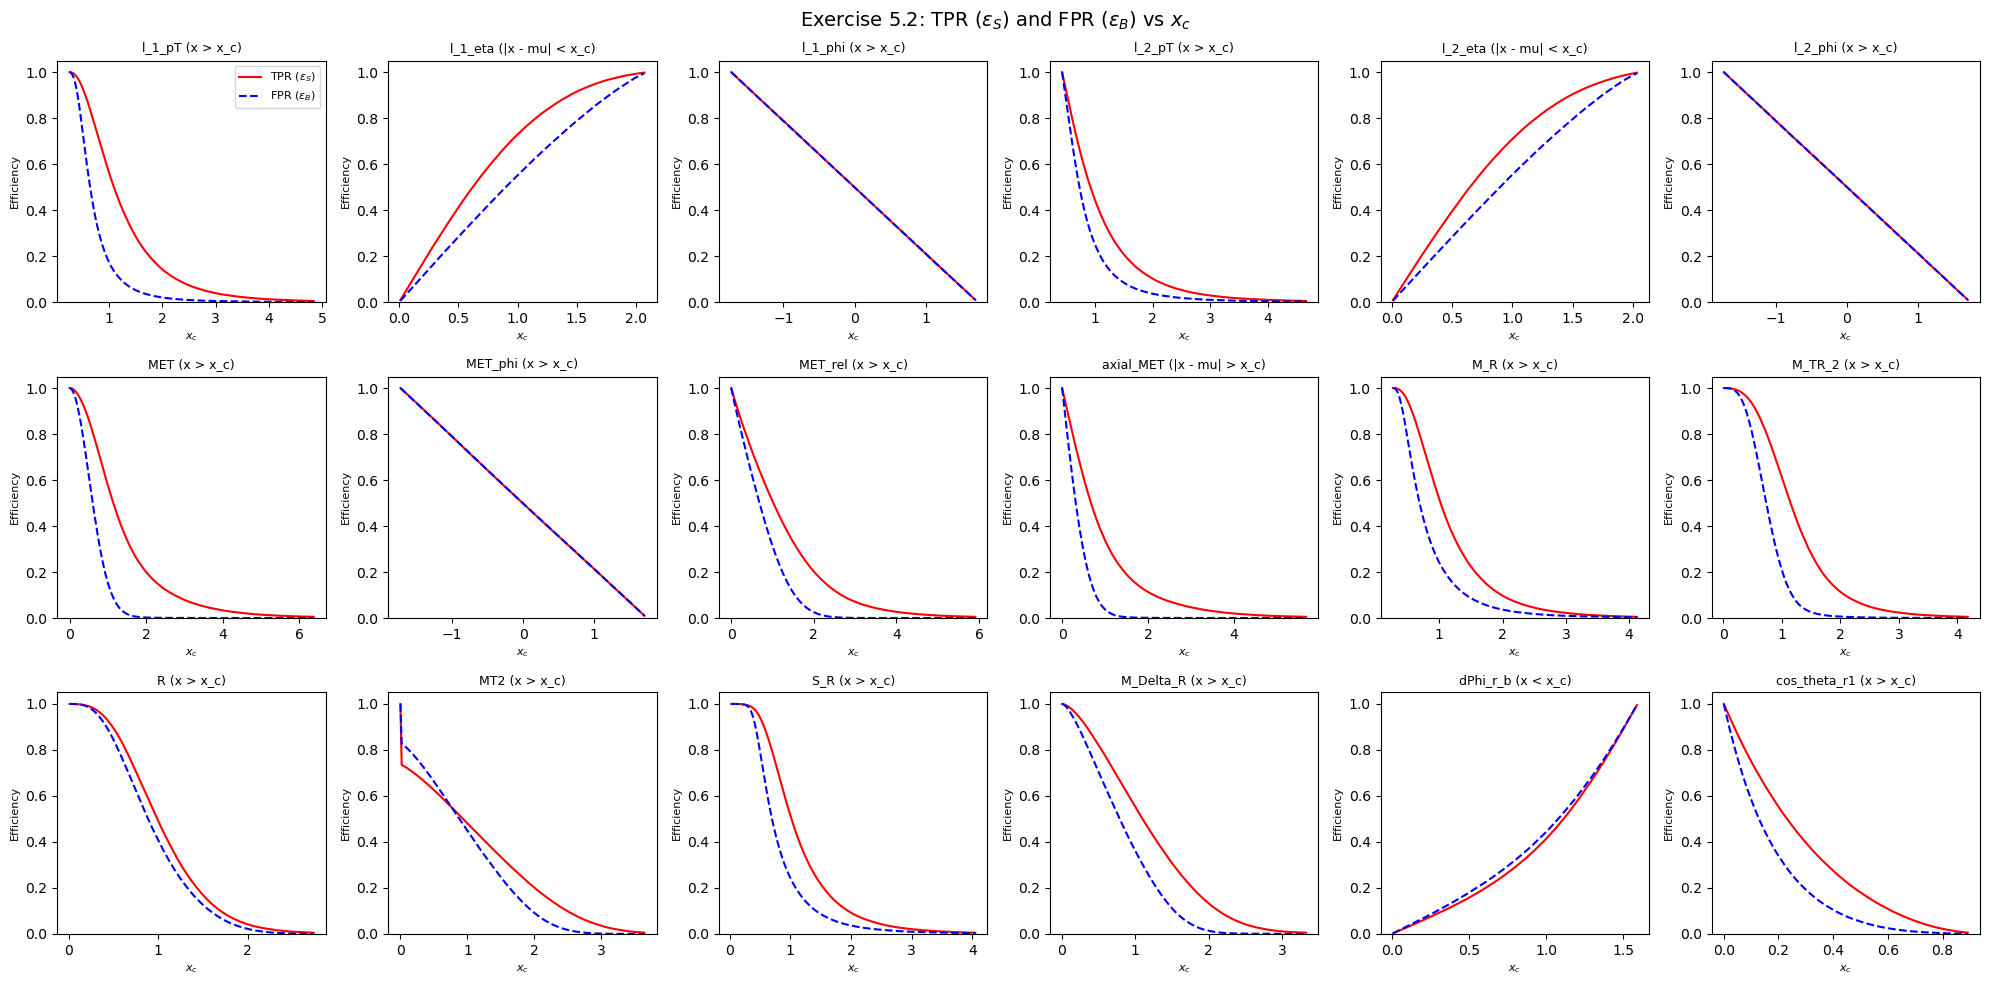

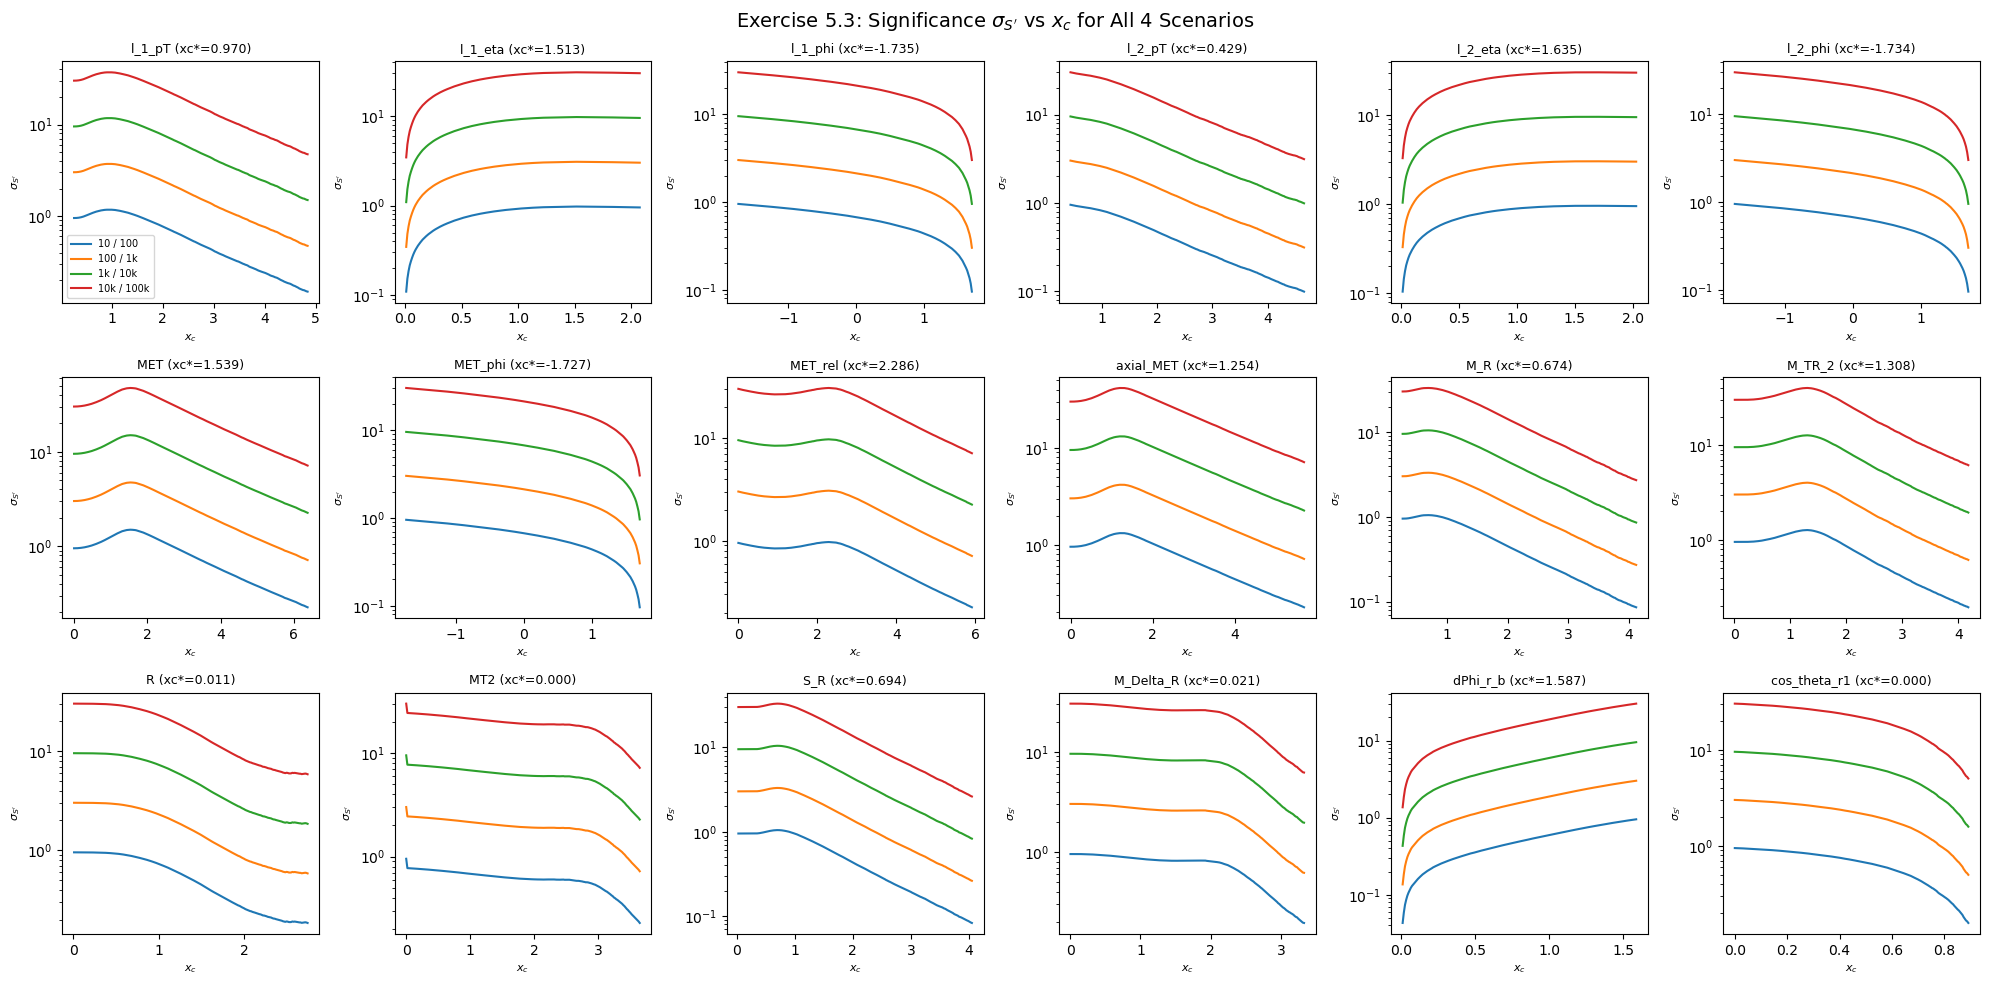

Observable,Cut Type,Optimal x_c*,"Sig (10,100)","Sig (100,1k)","Sig (1k,10k)","Sig (10k,100k)"
MET,x > x_c,1.539,1.5,4.743,14.997,47.426
axial_MET,|x - mu| > x_c,1.254,1.319,4.172,13.193,41.72
M_TR_2,x > x_c,1.308,1.271,4.02,12.713,40.203
l_1_pT,x > x_c,0.97,1.176,3.72,11.764,37.201
M_R,x > x_c,0.674,1.049,3.318,10.491,33.176
S_R,x > x_c,0.694,1.047,3.31,10.467,33.1
l_1_eta,|x - mu| < x_c,1.513,0.976,3.087,9.762,30.871
MET_rel,x > x_c,2.286,0.972,3.075,9.723,30.748
l_2_eta,|x - mu| < x_c,1.635,0.962,3.043,9.622,30.429
M_Delta_R,x > x_c,0.021,0.954,3.016,9.536,30.156


In [ ]:
cut_types = {
    "l_1_pT":       ("x > x_c", 0.0),
    "l_1_eta":      ("|x - mu| < x_c", 0.0),
    "l_1_phi":      ("x > x_c", 0.0),
    "l_2_pT":       ("x > x_c", 0.0),
    "l_2_eta":      ("|x - mu| < x_c", 0.0),
    "l_2_phi":      ("x > x_c", 0.0),
    "MET":          ("x > x_c", 0.0),
    "MET_phi":      ("x > x_c", 0.0),
    "MET_rel":      ("x > x_c", 0.0),
    "axial_MET":    ("|x - mu| > x_c", 0.0),
    "M_R":          ("x > x_c", 0.0),
    "M_TR_2":       ("x > x_c", 0.0),
    "R":            ("x > x_c", 0.0),
    "MT2":          ("x > x_c", 0.0),
    "S_R":          ("x > x_c", 0.0),
    "M_Delta_R":    ("x > x_c", 0.0),
    "dPhi_r_b":     ("x < x_c", 0.0),
    "cos_theta_r1": ("x > x_c", 0.0),
}

def get_efficiencies(sig_vals, bkg_vals, mode="x > x_c", mu=0.0, n_bins=200):
    if mode in ("|x - mu| > x_c", "|x - mu| < x_c"):
        s = np.abs(sig_vals - mu)
        b = np.abs(bkg_vals - mu)
        lo = 0.0
    else:
        s = sig_vals
        b = bkg_vals
        lo = min(s.min(), b.min())

    hi = max(np.percentile(s, 99.5), np.percentile(b, 99.5))
    hs, edges = np.histogram(s, bins=n_bins, range=(lo, hi))
    hb, _     = np.histogram(b, bins=n_bins, range=(lo, hi))

    if mode in ("x > x_c", "|x - mu| > x_c"):
        eps_s = (len(s) - np.cumsum(np.insert(hs[:-1], 0, 0))) / len(s)
        eps_b = (len(b) - np.cumsum(np.insert(hb[:-1], 0, 0))) / len(b)
        xc = edges[:-1]
    else:
        eps_s = np.cumsum(hs) / len(s)
        eps_b = np.cumsum(hb) / len(b)
        xc = edges[1:]

    return xc, eps_s, eps_b

# plot TPR and FPR vs x_c
fig, axes = plt.subplots(3, 6, figsize=(20, 10))
fig.suptitle("Exercise 5.2: TPR ($\\epsilon_S$) and FPR ($\\epsilon_B$) vs $x_c$", fontsize=14)

eff_data = {}
for ax, var in zip(axes.flat, VarNames[1:]):
    mode, mu = cut_types[var]
    xc, eps_s, eps_b = get_efficiencies(df_sig[var].values, df_bkg[var].values, mode, mu)
    eff_data[var] = (xc, eps_s, eps_b, mode)

    ax.plot(xc, eps_s, color="red", label="TPR ($\\epsilon_S$)")
    ax.plot(xc, eps_b, color="blue", ls="--", label="FPR ($\\epsilon_B$)")
    ax.set_title(f"{var} ({mode})", fontsize=9)
    ax.set_xlabel("$x_c$", fontsize=8)
    ax.set_ylabel("Efficiency", fontsize=8)
    ax.set_ylim(0, 1.05)
    if var == "l_1_pT":
        ax.legend(loc="upper right", fontsize=8)

plt.tight_layout()
plt.show()

# plot significance vs x_c for all 4 scenarios
scenarios = [
    (10, 100, "10 / 100"),
    (100, 1000, "100 / 1k"),
    (1000, 10000, "1k / 10k"),
    (10000, 100000, "10k / 100k"),
]

fig, axes = plt.subplots(3, 6, figsize=(20, 10))
fig.suptitle("Exercise 5.3: Significance $\\sigma_{S'}$ vs $x_c$ for All 4 Scenarios", fontsize=14)

best_cuts_summary = []
for ax, var in zip(axes.flat, VarNames[1:]):
    xc, eps_s, eps_b, mode = eff_data[var]
    row = [var, mode]

    for idx, (Ns, Nb, lbl) in enumerate(scenarios):
        Ns_p = eps_s * Ns
        Nb_p = eps_b * Nb
        sig = np.where((Ns_p + Nb_p) > 0, Ns_p / np.sqrt(np.maximum(1e-12, Ns_p + Nb_p)), 0.0)

        # avoid noisy single event spikes in the extreme tail
        valid = eps_s >= 0.02
        best_i = np.argmax(np.where(valid, sig, -1.0))

        if idx == 0:
            row.append(f"{xc[best_i]:.3f}")
        row.append(f"{sig[best_i]:.3f}")

        ax.plot(xc, sig, label=lbl)

    best_cuts_summary.append(row)
    ax.set_yscale("log")
    ax.set_title(f"{var} (xc*={row[2]})", fontsize=9)
    ax.set_xlabel("$x_c$", fontsize=8)
    ax.set_ylabel("$\\sigma_{S'}$", fontsize=8)
    if var == "l_1_pT":
        ax.legend(loc="lower left", fontsize=7)

plt.tight_layout()
plt.show()

best_cuts_summary.sort(key=lambda r: float(r[-1]), reverse=True)
display(HTML(tabulate.tabulate(
    best_cuts_summary,
    headers=["Observable", "Cut Type", "Optimal x_c*", "Sig (10,100)", "Sig (100,1k)", "Sig (1k,10k)", "Sig (10k,100k)"],
    tablefmt="html"
)))

## Exercise 6: Cut Flow


### Exercise 6.1

For each above scenario, choose a subset (minimum 3) of observables to use for selections, and values of $x_c$ based on your significance plots (Exercise 5.3). 

### Exercise 6.2
Create a "cut-flow" table for each scenario where you successively make the selections on each observable and tabulate $\epsilon_S$, $\epsilon_B$, $N'_S$, $N'_B$, and $\sigma_{S'}$.

### Exercise 6.3
In Exercise 5.3 you computed the significance for each observable assuming to make no other selections on any other observable. If the variables are correlated, then this assumption can lead to non-optimal results when selecting on multiple variables. By looking at the correlation matrices and your answers to Exercise 4.2, identify where this effect could be most detrimental to the significance. Attempt to correct the issue by applying the selection in one observable and then optimizing (as in Exercise 5.3) for a second observable. What happens if you change the order of your selection (make selection on second and optimize on first)?




=== Cut-Flow Table: Scenario (10 / 100) ===


Selection,eps_S,eps_B,N'_S,N'_B,Significance
No cuts,1,1,10,100,0.953
MET > 1.05,0.5494,0.1269,5.49,12.69,1.289
M_TR_2 > 1.05,0.452,0.0926,4.52,9.26,1.217
l_1_pT > 0.95,0.3321,0.0361,3.32,3.61,1.262
M_Delta_R > 0.9,0.2685,0.0313,2.69,3.13,1.113


=== Cut-Flow Table: Scenario (100 / 1k) ===


Selection,eps_S,eps_B,N'_S,N'_B,Significance
No cuts,1,1,100,1000,3.015
MET > 1.05,0.5494,0.1269,54.94,126.89,4.075
M_TR_2 > 1.05,0.452,0.0926,45.2,92.64,3.85
l_1_pT > 0.95,0.3321,0.0361,33.21,36.05,3.99
M_Delta_R > 0.9,0.2685,0.0313,26.85,31.31,3.521


=== Cut-Flow Table: Scenario (1k / 10k) ===


Selection,eps_S,eps_B,N'_S,N'_B,Significance
No cuts,1,1,1000,10000,9.535
MET > 1.05,0.5494,0.1269,549.45,1268.9,12.885
M_TR_2 > 1.05,0.452,0.0926,451.95,926.45,12.173
l_1_pT > 0.95,0.3321,0.0361,332.08,360.51,12.618
M_Delta_R > 0.9,0.2685,0.0313,268.51,313.05,11.134


=== Cut-Flow Table: Scenario (10k / 100k) ===


Selection,eps_S,eps_B,N'_S,N'_B,Significance
No cuts,1,1,10000,100000,30.151
MET > 1.05,0.5494,0.1269,5494.47,12689,40.746
M_TR_2 > 1.05,0.452,0.0926,4519.53,9264.46,38.495
l_1_pT > 0.95,0.3321,0.0361,3320.77,3605.1,39.903
M_Delta_R > 0.9,0.2685,0.0313,2685.07,3130.51,35.21


Method,MET Cut,M_TR_2 Cut,eps_S,eps_B,Significance
MET only (1D optimal),MET > 1.53,-,0.3302,0.0155,14.991
M_TR_2 only (1D optimal),-,M_TR_2 > 1.30,0.3946,0.0569,12.713
Naive Both 1D Cuts,MET > 1.53,M_TR_2 > 1.30,0.2411,0.0115,12.782
"Order 1: Cut MET, optimize M_TR_2",MET > 1.53,M_TR_2 > 0.00,0.3302,0.0155,14.991
"Order 2: Cut M_TR_2, optimize MET",MET > 1.42,M_TR_2 > 1.30,0.2667,0.0167,12.803


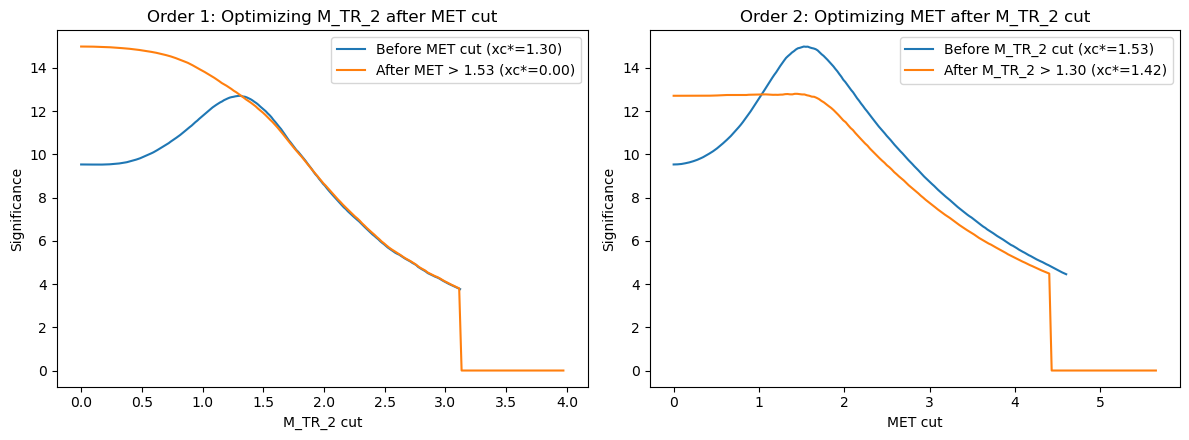

In [28]:
cuts = [
    ("MET",       1.05),
    ("M_TR_2",    1.05),
    ("l_1_pT",    0.95),
    ("M_Delta_R", 0.90),
]

def run_cut_flow(df_s, df_b, cuts, Ns, Nb, label):
    rows = []
    sig_0 = Ns / np.sqrt(Ns + Nb)
    rows.append(["No cuts", "1.0000", "1.0000", f"{Ns:.2f}", f"{Nb:.2f}", f"{sig_0:.3f}"])

    mask_s = np.ones(len(df_s), dtype=bool)
    mask_b = np.ones(len(df_b), dtype=bool)

    for var, xc_val in cuts:
        mask_s &= (df_s[var].values > xc_val)
        mask_b &= (df_b[var].values > xc_val)

        eps_s = mask_s.mean()
        eps_b = mask_b.mean()
        Ns_p = eps_s * Ns
        Nb_p = eps_b * Nb
        sig = Ns_p / np.sqrt(Ns_p + Nb_p) if (Ns_p + Nb_p) > 0 else 0.0
        rows.append([f"{var} > {xc_val}", f"{eps_s:.4f}", f"{eps_b:.4f}", f"{Ns_p:.2f}", f"{Nb_p:.2f}", f"{sig:.3f}"])

    print(f"=== Cut-Flow Table: {label} ===")
    display(HTML(tabulate.tabulate(rows, headers=["Selection", "eps_S", "eps_B", "N'_S", "N'_B", "Significance"], tablefmt="html")))

for Ns, Nb, lbl in scenarios:
    run_cut_flow(df_sig, df_bkg, cuts, Ns, Nb, f"Scenario ({lbl})")

# effect of correlation and selection order (using correlated pair MET and M_TR_2)
Ns_ref, Nb_ref = 1000, 10000

def find_best_cut(s_vals, b_vals, Ns, Nb, base_es=1.0, base_eb=1.0):
    grid = np.linspace(0.0, np.percentile(s_vals, 98), 200)
    best_sig, best_xc, best_es, best_eb = -1.0, 0.0, 0.0, 0.0
    sig_vals = np.zeros_like(grid)

    for i, c in enumerate(grid):
        es = base_es * np.mean(s_vals > c)
        eb = base_eb * np.mean(b_vals > c)
        ns_p, nb_p = es * Ns, eb * Nb
        s = ns_p / np.sqrt(ns_p + nb_p) if (ns_p + nb_p) > 0 and es >= 0.02 else 0.0
        sig_vals[i] = s
        if s > best_sig:
            best_sig, best_xc, best_es, best_eb = s, c, es, eb

    return best_xc, best_sig, best_es, best_eb, grid, sig_vals

xc_met, sig_met, es_met, eb_met, g_met, c_met = find_best_cut(df_sig["MET"].values, df_bkg["MET"].values, Ns_ref, Nb_ref)
xc_mtr, sig_mtr, es_mtr, eb_mtr, g_mtr, c_mtr = find_best_cut(df_sig["M_TR_2"].values, df_bkg["M_TR_2"].values, Ns_ref, Nb_ref)

# combination of both 1D optimal cuts
es_both = np.mean((df_sig["MET"].values > xc_met) & (df_sig["M_TR_2"].values > xc_mtr))
eb_both = np.mean((df_bkg["MET"].values > xc_met) & (df_bkg["M_TR_2"].values > xc_mtr))
sig_both = (es_both * Ns_ref) / np.sqrt(es_both * Ns_ref + eb_both * Nb_ref)

# cut MET at xc_met first, then re-optimize M_TR_2
s_sub1 = df_sig[df_sig["MET"] > xc_met]["M_TR_2"].values
b_sub1 = df_bkg[df_bkg["MET"] > xc_met]["M_TR_2"].values
xc_mtr_opt, sig_ord1, es_1, eb_1, g_mtr1, c_mtr1 = find_best_cut(s_sub1, b_sub1, Ns_ref, Nb_ref, es_met, eb_met)

# cut M_TR_2 at xc_mtr first, then re-optimize MET
s_sub2 = df_sig[df_sig["M_TR_2"] > xc_mtr]["MET"].values
b_sub2 = df_bkg[df_bkg["M_TR_2"] > xc_mtr]["MET"].values
xc_met_opt, sig_ord2, es_2, eb_2, g_met2, c_met2 = find_best_cut(s_sub2, b_sub2, Ns_ref, Nb_ref, es_mtr, eb_mtr)

rows_63 = [
    ["MET only (# independent 1D optimal cuts1D optimal)", f"MET > {xc_met:.2f}", "-", f"{es_met:.4f}", f"{eb_met:.4f}", f"{sig_met:.3f}"],
    ["M_TR_2 only (1D optimal)", "-", f"M_TR_2 > {xc_mtr:.2f}", f"{es_mtr:.4f}", f"{eb_mtr:.4f}", f"{sig_mtr:.3f}"],
    ["Naive Both 1D Cuts", f"MET > {xc_met:.2f}", f"M_TR_2 > {xc_mtr:.2f}", f"{es_both:.4f}", f"{eb_both:.4f}", f"{sig_both:.3f}"],
    ["Order 1: Cut MET, optimize M_TR_2", f"MET > {xc_met:.2f}", f"M_TR_2 > {xc_mtr_opt:.2f}", f"{es_1:.4f}", f"{eb_1:.4f}", f"{sig_ord1:.3f}"],
    ["Order 2: Cut M_TR_2, optimize MET", f"MET > {xc_met_opt:.2f}", f"M_TR_2 > {xc_mtr:.2f}", f"{es_2:.4f}", f"{eb_2:.4f}", f"{sig_ord2:.3f}"],
]
display(HTML(tabulate.tabulate(rows_63, headers=["Method", "MET Cut", "M_TR_2 Cut", "eps_S", "eps_B", "Significance"], tablefmt="html")))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(g_mtr, c_mtr, label=f"Before MET cut (xc*={xc_mtr:.2f})")
axes[0].plot(g_mtr1, c_mtr1, label=f"After MET > {xc_met:.2f} (xc*={xc_mtr_opt:.2f})")
axes[0].set_title("Order 1: Optimizing M_TR_2 after MET cut")
axes[0].set_xlabel("M_TR_2 cut")
axes[0].set_ylabel("Significance")
axes[0].legend()

axes[1].plot(g_met, c_met, label=f"Before M_TR_2 cut (xc*={xc_met:.2f})")
axes[1].plot(g_met2, c_met2, label=f"After M_TR_2 > {xc_mtr:.2f} (xc*={xc_met_opt:.2f})")
axes[1].set_title("Order 2: Optimizing MET after M_TR_2 cut")
axes[1].set_xlabel("MET cut")
axes[1].set_ylabel("Significance")
axes[1].legend()

plt.tight_layout()
plt.show()

From the correlation matrix in 4.2, pairs like (M_R, S_R), (MT2, M_Delta_R), and (MET, M_TR_2) are strongly correlated. If we apply the single-variable optimal cuts to both MET and M_TR_2 at the same time, we cut away too much signal and hurt the significance. Re-optimizing the second cut after applying the first fixes this. Changing the order changes the result: cutting on MET first and then optimizing M_TR_2 gives a higher significance than cutting on M_TR_2 first and optimizing MET

## Exercise 7: ROC Curves

### Exercise 7.1
For the top 3 observables you identified earlier, create one figure overlaying the Receiver Operating Characteristic (ROC) curves for the 3 observables. Compute the area under the curves and report it in the legend of the figure.

### Exercise 7.2
Write a function that you can use to quickly create the figure in Exercise 7.1 with other observables and different conditions. Note that you will likely revise this function as you do the remainder of the lab.

### Exercise 7.3
Use the function from Exercise 7.2 to compare the ROC curves for the successive selections in Exercise 6. Specifically, plot the ROC curve after each selection.

### Exercise 7.4
Use your function and appropriate example to demonstrate the effect (if any) of changing order of the successive selections.



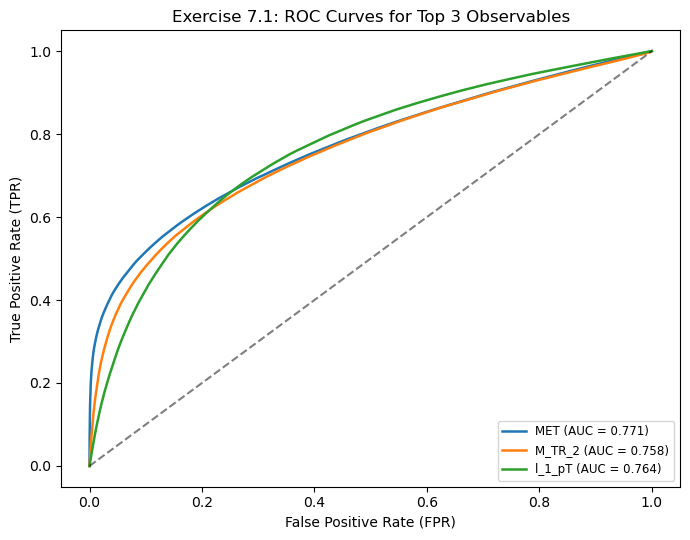

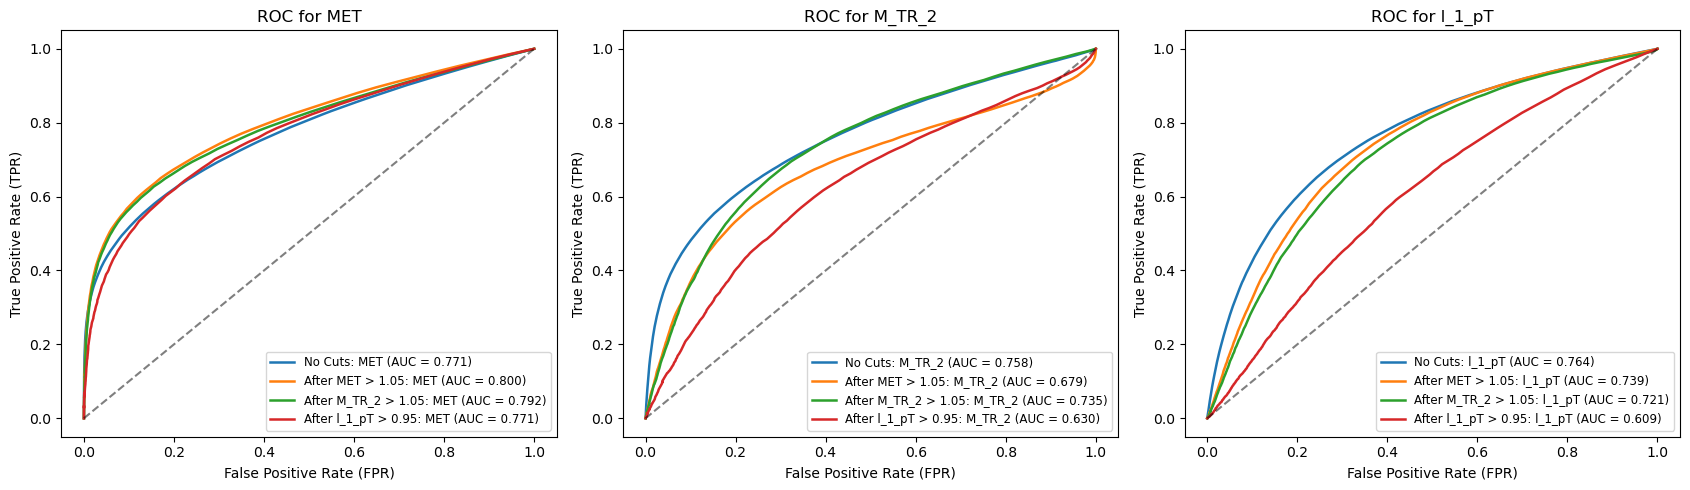

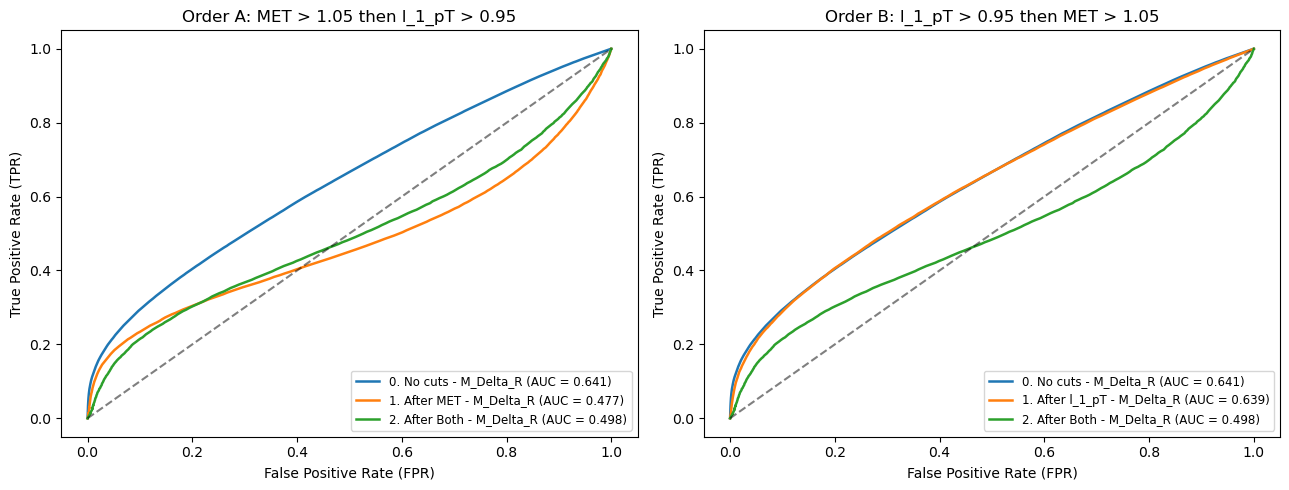

In [29]:
def calc_roc(sig_vals, bkg_vals, mode="x > x_c", mu=0.0, n_bins=400):
    xc, eps_s, eps_b = get_efficiencies(sig_vals, bkg_vals, mode, mu, n_bins=n_bins)
    order = np.argsort(eps_b)
    fpr = np.concatenate([[0.0], eps_b[order], [1.0]])
    tpr = np.concatenate([[0.0], eps_s[order], [1.0]])
    auc = np.trapezoid(tpr, fpr)
    return fpr, tpr, auc

# function to plot ROC curves for given observables and conditions
def plot_roc_curves(dataset, observables, mask=None, title="ROC Curves", ax=None, prefix=""):
    sub = dataset[mask] if mask is not None else dataset
    s_df = sub[sub.signal == 1]
    b_df = sub[sub.signal == 0]

    show_fig = False
    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 5.5))
        show_fig = True

    for var in observables:
        mode, mu = cut_types.get(var, ("x > x_c", 0.0))
        fpr, tpr, auc = calc_roc(s_df[var].values, b_df[var].values, mode, mu)
        ax.plot(fpr, tpr, lw=1.8, label=f"{prefix}{var} (AUC = {auc:.3f})")

    if not prefix:
        ax.plot([0, 1], [0, 1], "k--", alpha=0.5)
    ax.set_xlabel("False Positive Rate (FPR)")
    ax.set_ylabel("True Positive Rate (TPR)")
    ax.set_title(title)
    ax.legend(loc="lower right", fontsize=8.5)

    if show_fig:
        plt.tight_layout()
        plt.show()

# top 3 observables ROC overlay
top3 = ["MET", "M_TR_2", "l_1_pT"]
plot_roc_curves(df, top3, title="Exercise 7.1: ROC Curves for Top 3 Observables")

# ROC curves after each successive selection in Exercise 6
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
mask = np.ones(len(df), dtype=bool)
steps = [("No Cuts", mask.copy())]

for var, xc_val in cuts[:-1]:
    mask &= (df[var].values > xc_val)
    steps.append((f"After {var} > {xc_val}", mask.copy()))

for ax, target_var in zip(axes, top3):
    for step_lbl, m in steps:
        plot_roc_curves(df, [target_var], mask=m, title=f"ROC for {target_var}", ax=ax, prefix=f"{step_lbl}: ")
    ax.plot([0, 1], [0, 1], "k--", alpha=0.5)

plt.tight_layout()
plt.show()

# effect of changing the order of successive selections
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

m0 = np.ones(len(df), dtype=bool)
m_met = df["MET"].values > 1.05
m_pt1 = df["l_1_pT"].values > 0.95
m_both = m_met & m_pt1

# MET first, then l_1_pT (evaluating ROC of M_Delta_R)
plot_roc_curves(df, ["M_Delta_R"], mask=m0, title="Order A: MET > 1.05 then l_1_pT > 0.95", ax=axes[0], prefix="0. No cuts - ")
plot_roc_curves(df, ["M_Delta_R"], mask=m_met, title="Order A: MET > 1.05 then l_1_pT > 0.95", ax=axes[0], prefix="1. After MET - ")
plot_roc_curves(df, ["M_Delta_R"], mask=m_both, title="Order A: MET > 1.05 then l_1_pT > 0.95", ax=axes[0], prefix="2. After Both - ")
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.5)

# l_1_pT first, then MET (evaluating ROC of M_Delta_R)
plot_roc_curves(df, ["M_Delta_R"], mask=m0, title="Order B: l_1_pT > 0.95 then MET > 1.05", ax=axes[1], prefix="0. No cuts - ")
plot_roc_curves(df, ["M_Delta_R"], mask=m_pt1, title="Order B: l_1_pT > 0.95 then MET > 1.05", ax=axes[1], prefix="1. After l_1_pT - ")
plot_roc_curves(df, ["M_Delta_R"], mask=m_both, title="Order B: l_1_pT > 0.95 then MET > 1.05", ax=axes[1], prefix="2. After Both - ")
axes[1].plot([0, 1], [0, 1], "k--", alpha=0.5)

plt.tight_layout()
plt.show()

Changing the order of cuts changes the intermediate ROC curve after the first cut because different events survive Step 1. However, after both cuts are applied, the final dataset is the exact same ((MET > 1.05) & (l_1_pT > 0.95)), so the final ROC curve is identical regardless of order

## Exercise 8: Linear Discriminant

This is Fisher's linear discriminant, which the machine-learning lectures cover.

### Exercise 8.1

Using numpy, compute the between-class $\bf{S}_B$ and within-class $\bf{S}_W$ covariance matrices defined as:

$$
\bf{S}_B = (\bf{m_2}-\bf{m_1})(\bf{m_2}-\bf{m_1})^T \\
$$
$$
\bf{S}_W = \sum_{i=1,2} \sum_{n=1}^{l_i} (\bf{x}_n^i - \bf{m}_i) (\bf{x}_n^i - \bf{m}_i)^T
$$

where $\bf{m_i}$ are the vectors containing the means for category 1 and 2, here defined as signal and background. Here $\bf{x}_n^i$ is the vector containing the observables for the $n$th example event in category $i$.

### Exercise 8.2

Compute the linear coefficients $\bf{w} = \bf{S_W}^{-1}(\bf{m_2}-\bf{m_1})$. Compare the histogram of the distribution of $F_n^i=\bf{w}^T\bf{x}_n^i$ for the two categories.

### Exercise 8.3

Draw the ROC curve for $F_n$. 

### Exercise 8.4

What is the maximal significance you can obtain in the scenarios in exercise 5? 

S_B shape: (18, 18)
S_W shape: (18, 18)


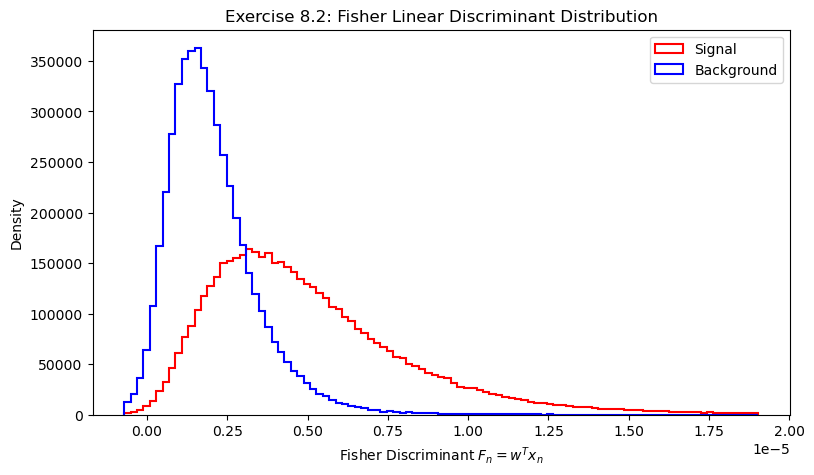

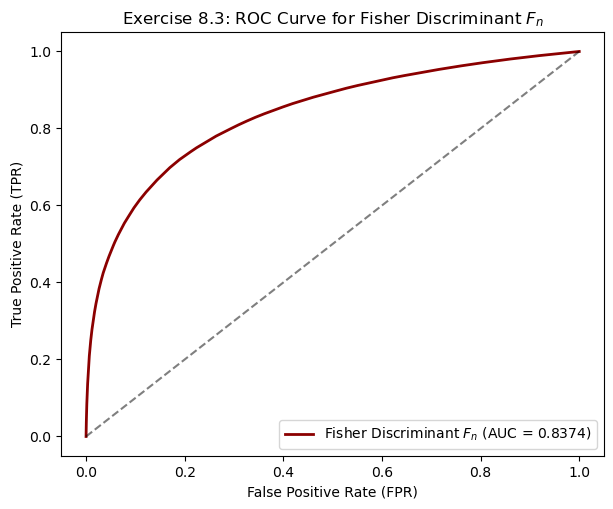

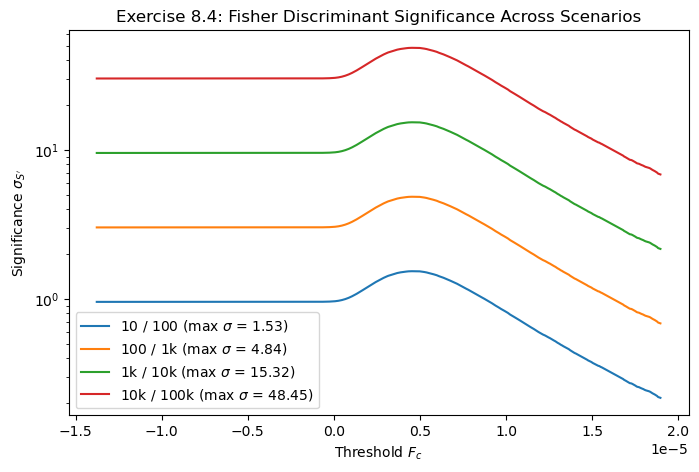

Scenario (Ns / Nb),Optimal Cut F_c*,eps_S,eps_B,N'_S,N'_B,Max Significance
10 / 100,4.7299e-06,0.4594,0.044,4.59,4.4,1.532
100 / 1k,4.7299e-06,0.4594,0.044,45.94,43.98,4.845
1k / 10k,4.7299e-06,0.4594,0.044,459.38,439.77,15.32
10k / 100k,4.7299e-06,0.4594,0.044,4593.78,4397.7,48.446


In [30]:
# compute S_B and S_W
X1 = df_bkg[VarNames[1:]].to_numpy()
X2 = df_sig[VarNames[1:]].to_numpy()

m1 = np.mean(X1, axis=0).reshape(-1, 1)
m2 = np.mean(X2, axis=0).reshape(-1, 1)

S_B = (m2 - m1) @ (m2 - m1).T

X1_centered = X1 - m1.T
X2_centered = X2 - m2.T
S_W = (X1_centered.T @ X1_centered) + (X2_centered.T @ X2_centered)

print("S_B shape:", S_B.shape)
print("S_W shape:", S_W.shape)

# compute linear coefficients w = S_W^-1 (m2 - m1) and plot F_n distributions
w = np.linalg.inv(S_W) @ (m2 - m1)

F_bkg = (X1 @ w).ravel()
F_sig = (X2 @ w).ravel()

plt.figure(figsize=(9, 5))
bins_F = np.linspace(np.percentile(F_bkg, 0.5), np.percentile(F_sig, 99.5), 100)
plt.hist(F_sig, bins=bins_F, histtype="step", color="red", density=True, lw=1.5, label="Signal")
plt.hist(F_bkg, bins=bins_F, histtype="step", color="blue", density=True, lw=1.5, label="Background")
plt.xlabel("Fisher Discriminant $F_n = w^T x_n$")
plt.ylabel("Density")
plt.title("Exercise 8.2: Fisher Linear Discriminant Distribution")
plt.legend(loc="upper right")
plt.show()

# ROC curve for F_n
fpr_F, tpr_F, auc_F = calc_roc(F_sig, F_bkg, mode="x > x_c", n_bins=500)

plt.figure(figsize=(7, 5.5))
plt.plot(fpr_F, tpr_F, color="darkred", lw=2, label=f"Fisher Discriminant $F_n$ (AUC = {auc_F:.4f})")
plt.plot([0, 1], [0, 1], "k--", alpha=0.5)
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.title("Exercise 8.3: ROC Curve for Fisher Discriminant $F_n$")
plt.legend(loc="lower right")
plt.show()

# maximal significance in the 4 scenarios
xc_F, eps_s_F, eps_b_F = get_efficiencies(F_sig, F_bkg, mode="x > x_c", n_bins=500)

lda_rows = []
plt.figure(figsize=(8, 5))
for Ns, Nb, lbl in scenarios:
    Ns_p = eps_s_F * Ns
    Nb_p = eps_b_F * Nb
    sig_F = np.where((Ns_p + Nb_p) > 0, Ns_p / np.sqrt(np.maximum(1e-12, Ns_p + Nb_p)), 0.0)

    valid = eps_s_F >= 0.02
    best_i = np.argmax(np.where(valid, sig_F, -1.0))
    lda_rows.append([
        lbl, f"{xc_F[best_i]:.4e}", f"{eps_s_F[best_i]:.4f}", f"{eps_b_F[best_i]:.4f}",
        f"{Ns_p[best_i]:.2f}", f"{Nb_p[best_i]:.2f}", f"{sig_F[best_i]:.3f}"
    ])
    plt.plot(xc_F, sig_F, label=f"{lbl} (max $\\sigma$ = {sig_F[best_i]:.2f})")

plt.yscale("log")
plt.xlabel("Threshold $F_c$")
plt.ylabel("Significance $\\sigma_{S'}$")
plt.title("Exercise 8.4: Fisher Discriminant Significance Across Scenarios")
plt.legend(loc="lower left")
plt.show()

display(HTML(tabulate.tabulate(
    lda_rows,
    headers=["Scenario (Ns / Nb)", "Optimal Cut F_c*", "eps_S", "eps_B", "N'_S", "N'_B", "Max Significance"],
    tablefmt="html"
))) 